<a href="https://colab.research.google.com/github/dherreraal/data_structures/blob/main/Clase_14/14_ED_MaxHeap_Insert_HeapSort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Max-Heap Insert y HeapSort
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Estructuras de Datos
---


## Índice de Contenido
1. Introducción y Repaso de Max-Heap
2. Inserción en Max-Heap
3. Construcción Eficiente de Montículos: Algoritmo BuildHeap en Tiempo Lineal $O(n)$
4. El Algoritmo de Ordenamiento HeapSort (Versión Ingenua vs. In-Place)
5. Ordenamiento Parcial (Partial Sorting) y Selección de los Top-K Elementos
6. Variantes Avanzadas: Montículos d-arios (d-ary Heaps) y Min-Heap
7. Demostraciones Prácticas en Java
8. Buenas Prácticas, Errores Frecuentes (Pitfalls) y Estabilidad
9. Ejercicios Prácticos
10. Bibliografía y Referencias
---


## 1. Introducción y Repaso de Max-Heap: Estructura y Propiedad de Orden

Un **montículo binario de máximos** (*Max-Heap*) es una estructura de datos no lineal basada en árboles binarios que optimiza las operaciones fundamentales de las colas de prioridad: inserción dinámica de elementos y consulta/extracción inmediata del elemento con la máxima prioridad.

Para que una estructura sea formalmente un Max-Heap, debe satisfacer de forma simultánea e invariable dos propiedades rigurosas:

1. **Propiedad Estructural (*Shape Property*):**
   * Es un **árbol binario casi completo** (*nearly complete binary tree*).
   * Todos los niveles del árbol están completamente llenos, con la posible excepción del último nivel (nivel $h$).
   * En el último nivel, todas las hojas se encuentran agrupadas de manera contigua y sin huecos de izquierda a derecha.
   * La altura de un montículo de $n$ nodos está estrictamente acotada por:
     $$h = \lfloor \log_2 n \rfloor$$

2. **Propiedad de Orden de Max-Heap (*Heap Property*):**
   * Para todo nodo $i$ distinto de la raíz, el valor almacenado en su nodo padre es mayor o igual que el valor almacenado en $i$:
     $$A[\text{parent}(i)] \ge A[i]$$
   * Como consecuencia directa de esta definición transitiva, el elemento de mayor valor de todo el conjunto siempre reside en la raíz del árbol ($A[0]$).

### Representación Compacta en Memoria (Arreglo Base 0)

Gracias a la propiedad estructural de árbol casi completo sin huecos, un Max-Heap no requiere punteros explícitos ni nodos vinculados en memoria dinámica. Puede almacenarse de forma óptima y contigua en un arreglo estándar mediante un recorrido por niveles (*level-order*).

En una indexación basada en cero (**base 0**), las relaciones de parentesco entre cualquier nodo en el índice $i$ y sus familiares se calculan mediante aritmética entera elemental en tiempo constante $O(1)$:

| Relación Genealógica | Fórmula Aritmética (Base 0) | Operador Binario Equivalente | Condición de Validez |
| :--- | :--- | :--- | :--- |
| **Padre** | $\text{parent}(i) = \lfloor (i - 1) / 2 \rfloor$ | `(i - 1) >> 1` | Válido si $i > 0$ (la raíz no tiene padre) |
| **Hijo Izquierdo** | $\text{leftChild}(i) = 2i + 1$ | `(i << 1) + 1` | Válido si $2i + 1 < \text{size}$ |
| **Hijo Derecho** | $\text{rightChild}(i) = 2i + 2$ | `(i << 1) + 2` | Válido si $2i + 2 < \text{size}$ |
| **Es Nodo Hoja** | $i \ge \lfloor n / 2 \rfloor$ | `i >= (size >> 1)` | Nodos sin descendientes |
| **Último Nodo No Hoja**| $\lfloor (n - 2) / 2 \rfloor$ | `(size - 2) >> 1` | Pivote para construcción bottom-up |

---

### Resumen de Operaciones Primarias y Complejidades Asintóticas

| Operación | Signatura en Java | Peor Caso | Caso Promedio | Espacio Auxiliar | Descripción Operacional |
| :--- | :--- | :---: | :---: | :---: | :--- |
| `getMax` / `peek` | `int getMax()` | $O(1)$ | $O(1)$ | $O(1)$ | Retorna el valor en la raíz ($A[0]$) sin removerlo. |
| `insert` | `void insert(int val)` | $O(\log n)$ | $O(1)$ amort. | $O(1)$ | Agrega `val` al final y ejecuta `siftUp`. |
| `extractMax` | `int extractMax()` | $O(\log n)$ | $O(\log n)$ | $O(1)$ | Remueve la raíz, coloca la última hoja y ejecuta `siftDown`. |
| `siftUp` | `void siftUp(int i)` | $O(\log n)$ | $O(1)$ | $O(1)$ | Flota el elemento hacia la raíz mientras sea mayor que su padre. |
| `siftDown` | `void siftDown(int i, int n)` | $O(\log n)$ | $O(\log n)$ | $O(1)$ | Hunde el elemento intercambiándolo con el mayor de sus hijos. |
| `buildHeap` | `void buildHeap(int[] a)` | $O(n)$ | $O(n)$ | $O(1)$ | Construcción ascendente (*bottom-up*) de Floyd. |
| `heapSort` | `void heapSort(int[] a)` | $O(n \log n)$ | $O(n \log n)$ | $O(1)$ | Ordenamiento in-place no recursivo. |


## 2. Inserción en Max-Heap: Mecánica Detallada y Análisis de Invariantes

La inserción de una nueva clave $k$ en un Max-Heap de tamaño $n$ debe garantizar que, al finalizar el proceso, la estructura resultante continúe satisfaciendo estrictamente tanto la **propiedad de forma** como la **propiedad de orden**. Para lograrlo de forma óptima, el algoritmo opera en dos fases desacopladas:

### Mecánica Paso a Paso

1. **Inserción Estructural en la Próxima Hoja Disponible:**
   * El nuevo valor $k$ se posiciona en el primer índice libre del arreglo: $A[n]$ (donde $n = \text{size}$).
   * Inmediatamente se incrementa el contador de elementos: $\text{size} \leftarrow \text{size} + 1$.
   * **Invariante:** Al colocarlo en la posición contigua del arreglo, se preserva automáticamente y sin costo la propiedad de árbol binario casi completo (no se generan huecos en el nivel inferior).

2. **Restauración del Orden mediante `SiftUp` (Flotación):**
   * El elemento recién insertado puede violar la propiedad de orden si su valor supera al de su padre ($A[i] > A[\text{parent}(i)]$).
   * Se compara $A[i]$ con $A[\text{parent}(i)]$. Si $A[i] > A[\text{parent}(i)]$, se intercambian los dos elementos.
   * El índice bajo examen se actualiza a la posición del padre: $i \leftarrow \text{parent}(i)$.
   * Este proceso iterativo se repite mientras $i > 0$ y la condición de violación persista. Se detiene tan pronto como $A[i] \le A[\text{parent}(i)]$ o cuando el nodo alcanza la raíz ($i = 0$).

---

### Análisis Riguroso de Invariantes Durante `SiftUp`

Durante la ejecución de `siftUp`, se mantiene un invariante de bucle fundamental:
* **Invariante de Arista Única:** En cada paso de la flotación, existe a lo sumo **una única arista en violación** en todo el árbol, específicamente entre el nodo actual $i$ y su padre $\text{parent}(i)$.
* Todos los demás subárboles disjuntos del montículo son Max-Heaps válidos e intactos.
* Al intercambiar $A[i]$ con $A[\text{parent}(i)]$, como $A[i] > A[\text{parent}(i)]$ y por hipótesis inductiva el padre original era mayor o igual que el hermano de $i$, el nuevo valor ubicado en la posición del padre es estrictamente mayor que ambos hijos en ese nivel. Por ende, la propiedad de Max-Heap queda localmente satisfecha en ese subárbol y la violación solo puede propagarse hacia arriba.

### Análisis Asintótico de Inserción
* **Peor Caso:** El nuevo elemento es mayor que todos los nodos preexistentes en el montículo. Debe ascender desde la hoja más profunda hasta la raíz, recorriendo toda la altura del árbol $h = \lfloor \log_2 n \rfloor$. Requiere $O(\log n)$ comparaciones e intercambios.
* **Caso Promedio:** Para datos con distribución aleatoria uniforme, aproximadamente el 50% de los nodos residen en el último nivel (las hojas) y la probabilidad de ascender múltiples niveles decrece exponencialmente con la profundidad. Por tanto, el número esperado de intercambios es $O(1)$.

---

### Traza Gráfica Detallada: Inserción del Valor 32

A continuación se ilustra la traza formal de inserción del elemento $k = 32$ en un Max-Heap preexistente de 8 nodos, detallando los intercambios sucesivos, el aislamiento de la arista en violación y la actualización simultánea del arreglo en memoria contigua:


<div align="center">
  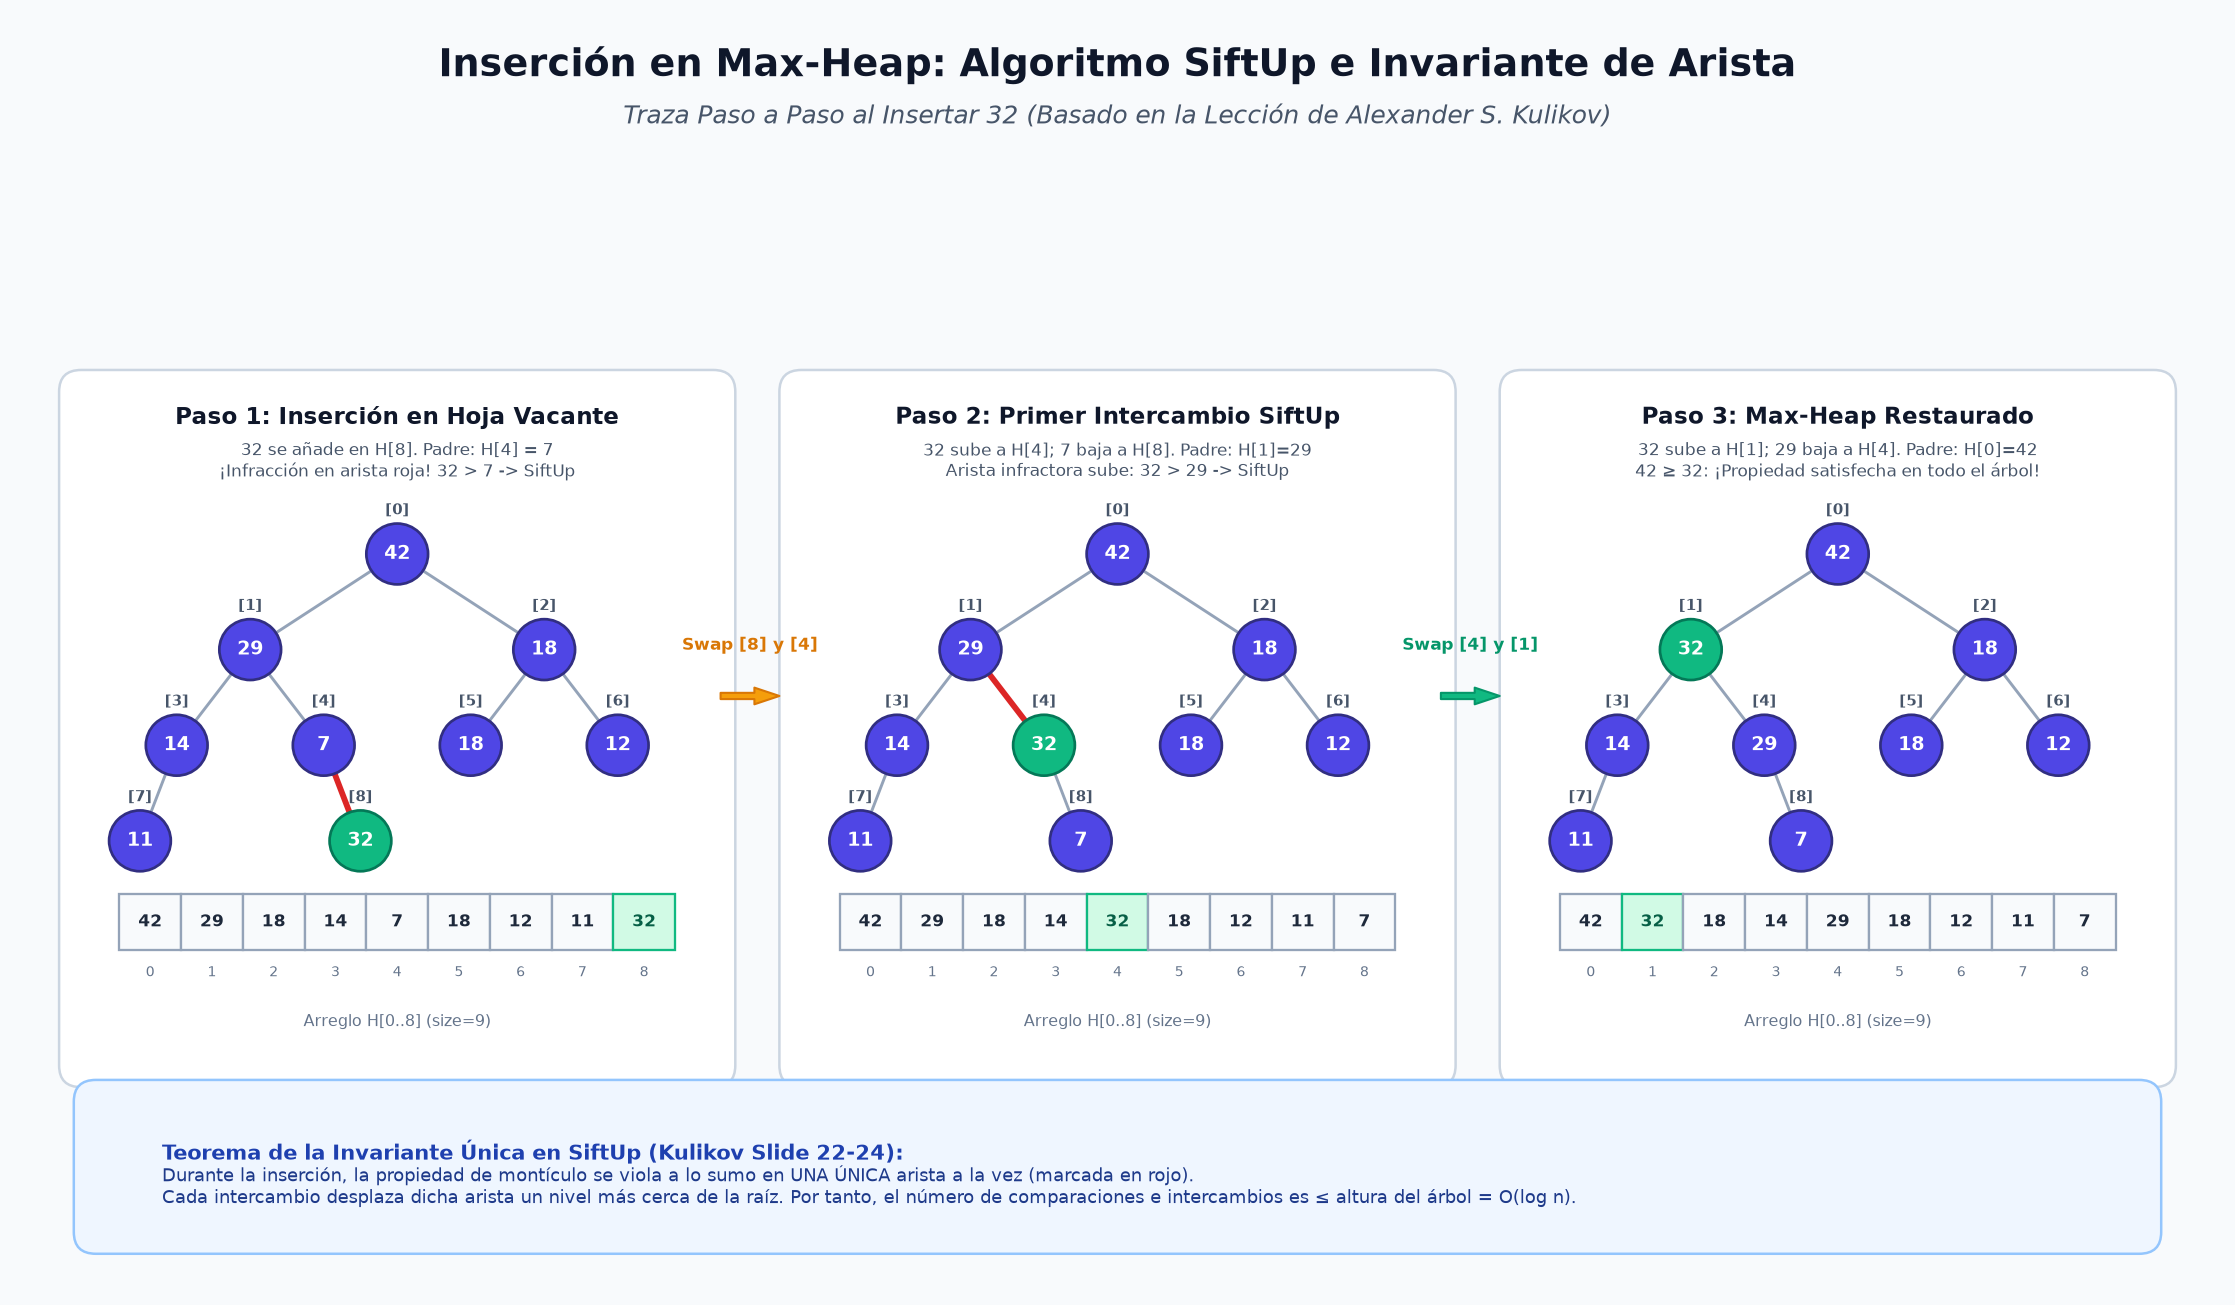
</div>


### Tabla de Traza Operacional: Inserción del Valor 32

| Paso | Índice Actual ($i$) | Valor ($A[i]$) | Padre ($p$) | Valor Padre ($A[p]$) | ¿$A[i] > A[p]$? | Acción Ejecutada | Estado del Arreglo |
| :---: | :---: | :---: | :---: | :---: | :---: | :--- | :--- |
| **0** | $i = 8$ | 32 | $p = 3$ | 12 | **Sí** ($32 > 12$) | Colocar 32 en $A[8]$. Se detecta violación con padre. | `[42, 29, 18, 12, 14, 7, 11, 5, 32]` |
| **1** | $i = 8 \to 3$ | 32 | $p = 1$ | 29 | **Sí** ($32 > 29$) | `swap(8, 3)`. El 32 asciende al índice 3; 12 desciende al 8. | `[42, 29, 18, 32, 14, 7, 11, 5, 12]` |
| **2** | $i = 3 \to 1$ | 32 | $p = 0$ | 42 | **No** ($32 \le 42$) | `swap(3, 1)`. El 32 asciende al índice 1; 29 desciende al 3. | `[42, 32, 18, 29, 14, 7, 11, 5, 12]` |
| **Fin**| $i = 1$ | 32 | $p = 0$ | 42 | Condición satisfecha | $32 \le A[0]$ (42). Se detiene `siftUp`. Invariante restaurado. | `[42, 32, 18, 29, 14, 7, 11, 5, 12]` |


## 3. Construcción Eficiente de Montículos: Algoritmo BuildHeap en Tiempo Lineal $O(n)$

Dado un arreglo arbitrario de $n$ elementos desordenados, el problema de construcción de montículo consiste en reorganizar sus posiciones in-place para que satisfaga la propiedad de Max-Heap.

Existen dos estrategias conceptuales con complejidades asintóticas diametralmente distintas:

### Estrategia A: Inserciones Repetidas (Enfoque Ingenuo Top-Down)
* Se comienza con un montículo conceptualmente vacío de tamaño 1 ($A[0]$) y se van insertando sucesivamente los elementos restantes $A[1], A[2], \dots, A[n-1]$ llamando a `siftUp` para cada uno.
* Dado que el $i$-ésimo elemento puede ascender hasta una altura $\lfloor \log_2 i \rfloor$, el trabajo total acumulado es:
  $$\sum_{i=1}^n O(\log i) = O(\log(n!)) = O(n \log n)$$

### Estrategia B: Algoritmo de Floyd (Enfoque Óptimo Bottom-Up)
Robert W. Floyd (1964) demostró que un montículo puede construirse en tiempo **estrictamente lineal $O(n)$**:
1. **Identificación de Hojas Triviales:** Todos los nodos desde el índice $\lfloor n / 2 \rfloor$ hasta $n - 1$ son hojas del árbol. Por definición, un árbol de un solo nodo es trivialmente un Max-Heap válido. No requieren ningún trabajo.
2. **Procesamiento Ascendente de Nodos Internos:** Se inicia en el **último nodo no hoja**, ubicado exactamente en el índice:
   $$i_{\text{inicio}} = \left\lfloor \frac{n - 2}{2} \right\rfloor$$
3. Se itera en reversa desde $i_{\text{inicio}}$ decreciendo hasta la raíz ($i = 0$), invocando la rutina `siftDown(A, i, n)` en cada paso.
4. Cuando se procesa el nodo $i$, sus dos subárboles (hijo izquierdo e hijo derecho) ya han sido procesados previamente y son Max-Heaps válidos. Al aplicar `siftDown(i)`, el subárbol con raíz en $i$ queda transformado en un Max-Heap válido.

---

### Demostración Matemática y Geométrica de la Complejidad $O(n)$

¿Por qué Floyd logra $O(n)$ mientras que las inserciones repetidas toman $O(n \log n)$?
* En el enfoque ingenuo con `siftUp`, la gran mayoría de los nodos (las hojas en los niveles más profundos) pueden ascender la distancia máxima ($h$).
* En el algoritmo de Floyd con `siftDown`, la distribución del esfuerzo se invierte: la inmensa mayoría de los nodos están cerca de la base y solo pueden hundirse distancias muy cortas ($0$ o $1$ pasos), mientras que únicamente la raíz puede hundirse la distancia completa $h$.

Formalmente, en un árbol binario casi completo de $n$ nodos y altura $H = \lfloor \log_2 n \rfloor$:
* El número de nodos a altura $k$ (donde las hojas tienen altura $k = 0$ y la raíz altura $k = H$) está acotado por:
  $$N_k \le \left\lceil \frac{n}{2^{k+1}} \right\rceil$$
* El costo máximo de aplicar `siftDown` en un nodo a altura $k$ es proporcional a su altura: $c \cdot k$.
* El trabajo total $T(n)$ realizado por `buildHeap` es la suma sobre todas las alturas posibles:
  $$T(n) \le \sum_{k=0}^{\lfloor \log_2 n \rfloor} \left\lceil \frac{n}{2^{k+1}} \right\rceil \cdot c \cdot k \le c n \sum_{k=0}^\infty \frac{k}{2^{k+1}} = \frac{c n}{2} \sum_{k=1}^\infty \frac{k}{2^k}$$

Evaluamos la serie geométrica aritmético-geométrica $S = \sum_{k=1}^\infty \frac{k}{2^k}$:
$$S = \frac{1}{2} + \frac{2}{4} + \frac{3}{8} + \frac{4}{16} + \frac{5}{32} + \dots$$
Multiplicamos toda la ecuación por $\frac{1}{2}$:
$$\frac{1}{2} S = \frac{1}{4} + \frac{2}{8} + \frac{3}{16} + \frac{4}{32} + \dots$$
Restamos la segunda ecuación de la primera:
$$S - \frac{1}{2} S = \frac{1}{2} + \left(\frac{2}{4} - \frac{1}{4}\right) + \left(\frac{3}{8} - \frac{2}{8}\right) + \left(\frac{4}{16} - \frac{3}{16}\right) + \dots$$
$$\frac{1}{2} S = \frac{1}{2} + \frac{1}{4} + \frac{1}{8} + \frac{1}{16} + \dots$$
La serie infinita resultante es una suma geométrica estándar con primer término $a = \frac{1}{2}$ y razón $r = \frac{1}{2}$:
$$\frac{1}{2} S = \frac{\frac{1}{2}}{1 - \frac{1}{2}} = 1 \implies S = 2$$

Sustituyendo el valor $S = 2$ en la expresión del tiempo total:
$$T(n) \le \frac{c n}{2} \cdot 2 = c n = O(n)$$

¡La cota es estrictamente lineal en el número de elementos!


<div align="center">
  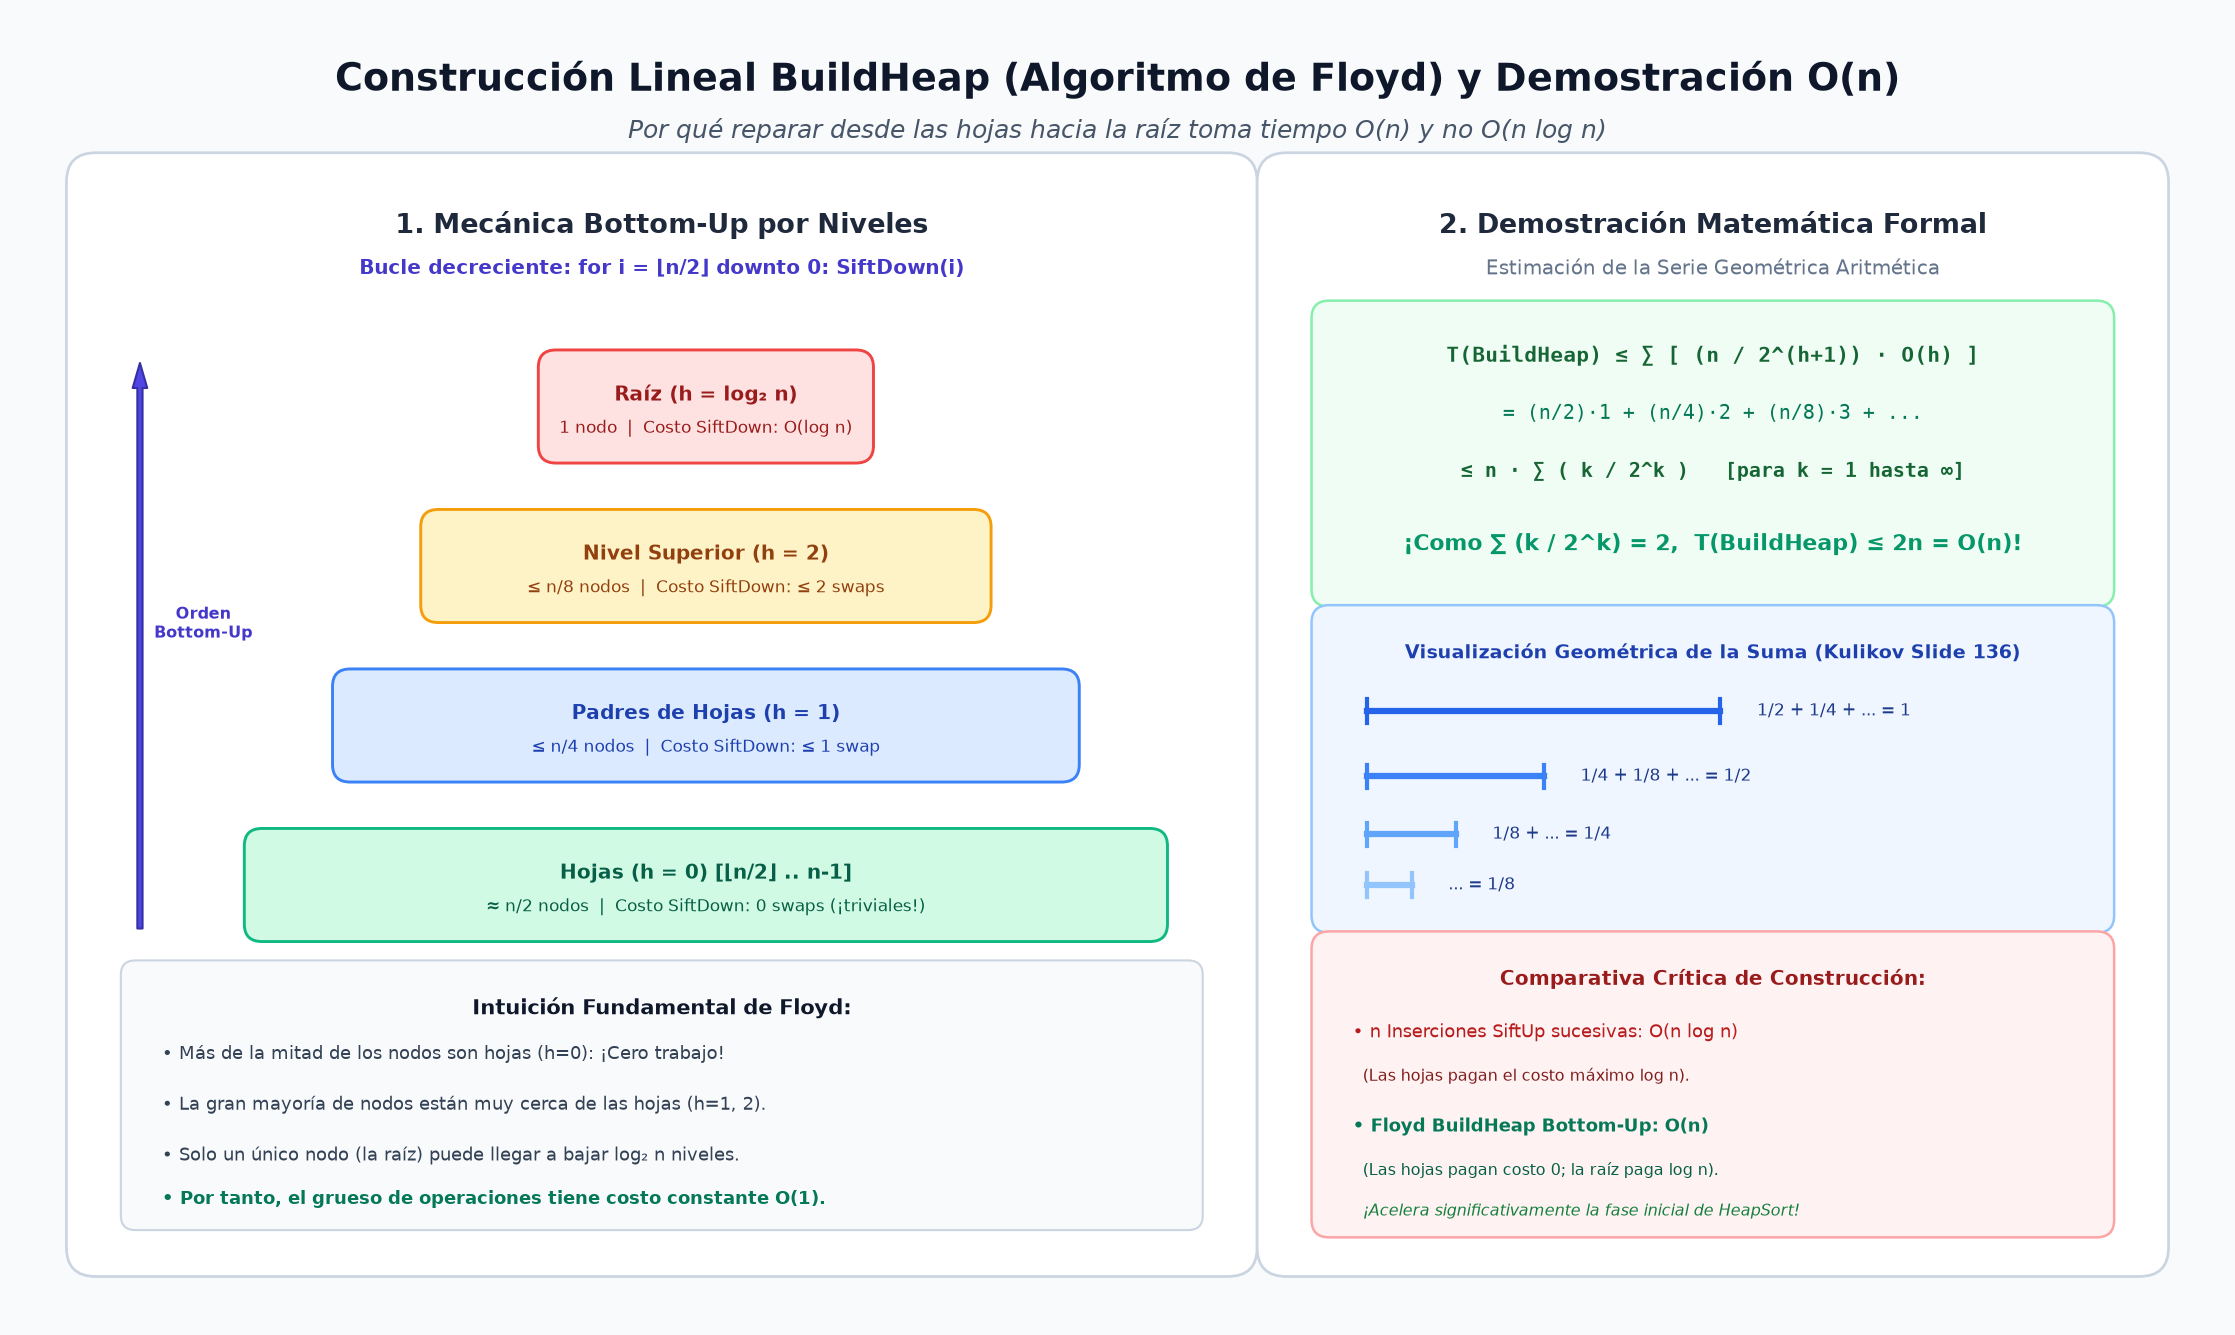
</div>


## 4. El Algoritmo de Ordenamiento HeapSort (Versión Ingenua vs. In-Place)

**HeapSort** es un algoritmo de ordenamiento por comparación inventado por J. W. J. Williams (1964) y perfeccionado por Robert W. Floyd. Puede interpretarse como una optimización asintótica de *Selection Sort*: mientras que Selection Sort busca el elemento máximo en una lista no ordenada en $O(n)$ mediante búsqueda lineal (resultando en $O(n^2)$), HeapSort utiliza la estructura de Max-Heap para extraer el máximo en tiempo logarítmico $O(\log n)$.

### Versión Ingenua (Con Arreglo Auxiliar)
1. Construir un Max-Heap con los $n$ elementos del arreglo original ($O(n)$).
2. Extraer sucesivamente el elemento máximo con `extractMax()` e insertarlo de derecha a izquierda en un nuevo arreglo auxiliar `result[n-1], result[n-2], \dots, result[0]`.
3. Copiar los elementos del arreglo auxiliar de vuelta al arreglo original.
* **Costo Temporal:** $O(n \log n)$.
* **Costo Espacial:** $O(n)$ memoria adicional requerida para el arreglo auxiliar.

---

### Versión Canónica In-Place ($O(1)$ Espacio Auxiliar)

La elegancia del algoritmo de Williams y Floyd radica en que **no requiere ningún arreglo auxiliar**, ordenando el arreglo original directamente sobre su propio espacio de memoria mediante partición contigua:

1. **Fase 1: Construcción del Max-Heap ($O(n)$)**
   * Se ejecuta Floyd's `buildHeap` directamente sobre el arreglo original `arr`.
   * Al finalizar la Fase 1, el elemento máximo global reside en `arr[0]`.

2. **Fase 2: Extracciones Sucesivas e Inversión In-Place ($O(n \log n)$)**
   * Se define un límite de frontera `end` que inicialmente apunta al último índice del arreglo: $\text{end} = n - 1$.
   * En cada iteración mientras $\text{end} > 0$:
     1. **Intercambio Raíz-Fin:** Se intercambia el elemento máximo actual `arr[0]` con el elemento en la frontera `arr[end]`:
        $$\text{swap}(arr, 0, \text{end})$$
     2. **Congelamiento en Sufijo Ordenado:** El valor colocado en `arr[end]` queda permanentemente fijado en su posición final ordenada.
     3. **Reducción del Prefijo de Montículo:** La frontera se decrementa ($\text{end} \leftarrow \text{end} - 1$). El tamaño del montículo activo ahora es $\text{end}$.
     4. **Restauración del Montículo:** El nuevo elemento temporal en `arr[0]` (antigua hoja) puede violar la propiedad de Max-Heap. Se llama a `siftDown(arr, 0, end)` para que descienda a su posición correcta dentro del prefijo activo $[0 \dots \text{end}-1]$.

Al finalizar el bucle (cuando $\text{end} = 0$), todo el arreglo queda estrictamente ordenado en **orden ascendente**.

---

### Partición de Memoria en HeapSort In-Place

En cualquier instante de la Fase 2, el arreglo se divide conceptualmente en dos regiones disjuntas contiguas:
$$\underbrace{[A[0], A[1], \dots, A[\text{end}-1]]}_{\textbf{Prefijo: Montículo Activo (Max-Heap)}} \quad \Big| \quad \underbrace{[A[\text{end}], A[\text{end}+1], \dots, A[n-1]]}_{\textbf{Sufijo: Elementos Ordenados Crecientes}}$$

* Todo elemento perteneciente al montículo activo es menor o igual que cualquier elemento perteneciente al sufijo ordenado:
  $$\forall i < \text{end}, \quad \forall j \ge \text{end}: \quad A[i] \le A[j]$$


<div align="center">
  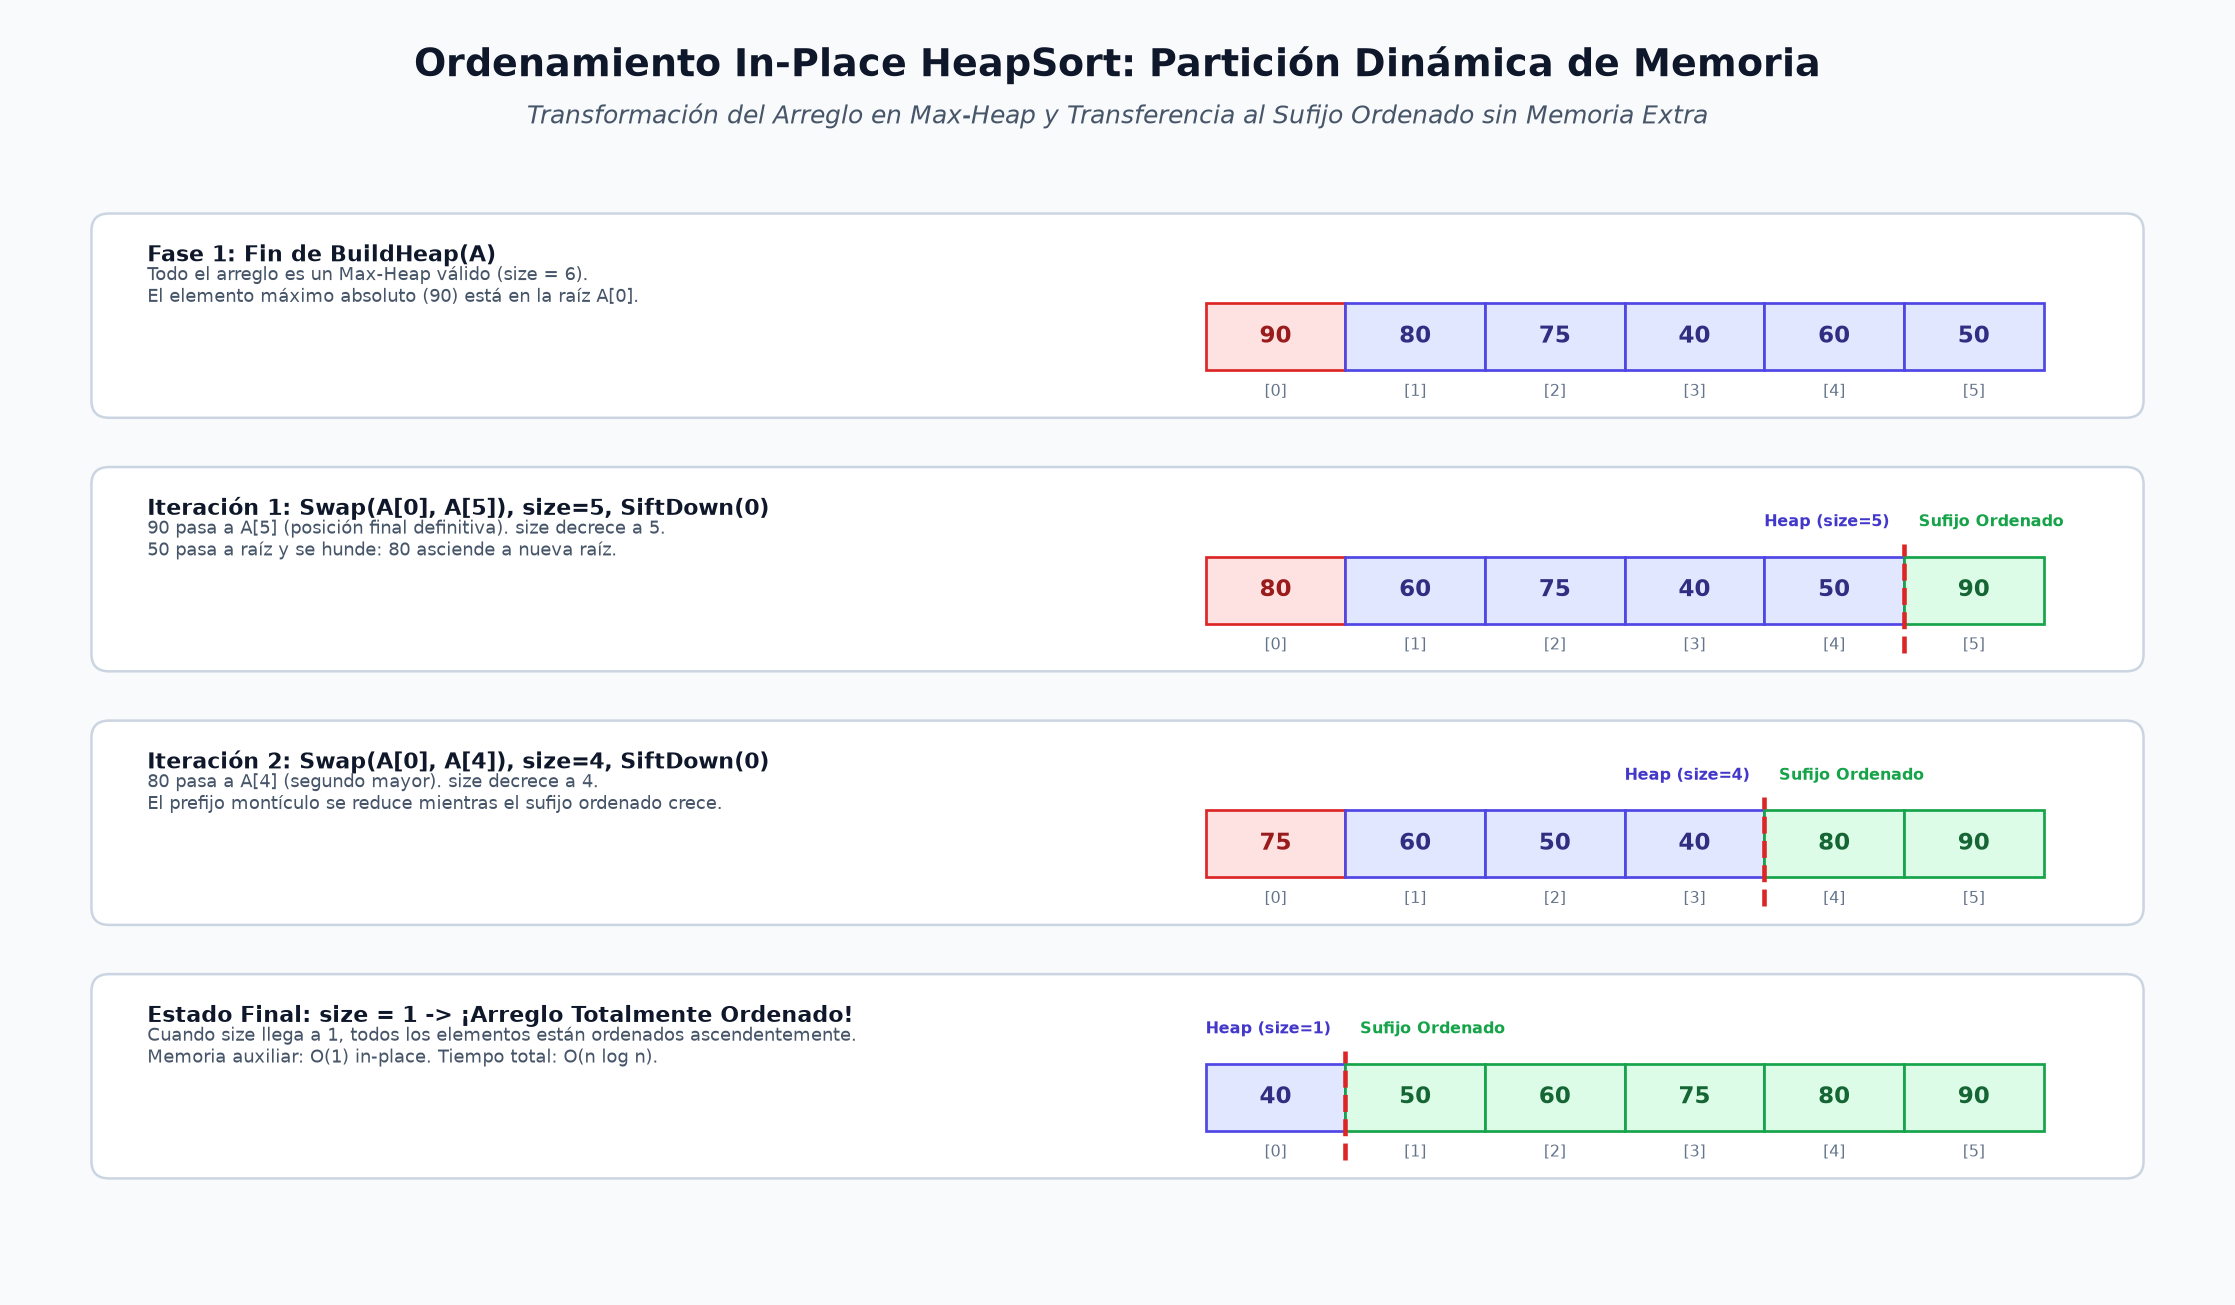
</div>


### Matriz de Complejidad Comparativa de HeapSort

| Métrica / Algoritmo | HeapSort | QuickSort (Clásico) | MergeSort | IntroSort (C++ `std::sort`) |
| :--- | :---: | :---: | :---: | :---: |
| **Mejor Caso** | $O(n \log n)$ / $O(n)$* | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ |
| **Caso Promedio** | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ |
| **Peor Caso** | $O(n \log n)$ | $O(n^2)$ | $O(n \log n)$ | $O(n \log n)$ |
| **Espacio Auxiliar** | $O(1)$ (Estricto in-place) | $O(\log n)$ (Pila de llamadas) | $O(n)$ (Buffer auxiliar) | $O(\log n)$ |
| **Estabilidad** | **Inestable** | **Inestable** | **Estable** | **Inestable** |
| **Rendimiento de Caché** | Regular (Saltos no locales) | Excelente (Acceso secuencial) | Bueno | Excelente |

*\*Nota:* El mejor caso de HeapSort es $O(n)$ cuando todos los elementos del arreglo son idénticos, ya que `siftDown` se detiene en la primera comparación al no detectar hijos mayores.


## 5. Ordenamiento Parcial (Partial Sorting) y Selección de los Top-K Elementos

En múltiples aplicaciones de ciencia de datos, motores de búsqueda y sistemas en tiempo real, no se requiere ordenar la totalidad de un conjunto de datos masivo de $n$ elementos, sino únicamente obtener los **$k$ elementos más grandes** (o más pequeños) en orden relativo (ej. las 10 noticias más relevantes entre 10 millones de artículos).

### El Dilema del Ordenamiento Total vs. Parcial
* **Ordenar todo el arreglo:** Aplicar QuickSort, MergeSort o HeapSort completo toma $O(n \log n)$ tiempo y desecha el orden de los $n - k$ elementos restantes.
* **Ordenamiento Parcial con Max-Heap:**
  1. Construir un Max-Heap in-place sobre el arreglo de datos original mediante Floyd en tiempo **$O(n)$**.
  2. Ejecutar exactamente $k$ operaciones de extracción del máximo (`extractMax`), donde cada extracción toma $O(\log n)$ tiempo:
     $$k \times O(\log n) = O(k \log n)$$
  3. **Complejidad Temporal Total:**
     $$T(n, k) = O(n + k \log n)$$

### Análisis del Umbral de Eficiencia Asintótica
¿Cuándo es asintóticamente superior este enfoque frente al ordenamiento completo?
* Si $k \le \frac{n}{\log n}$, entonces:
  $$k \log n \le \left(\frac{n}{\log n}\right) \log n = n \implies O(n + k \log n) = O(n)$$
  ¡El algoritmo resuelve la selección y ordenamiento de los $k$ máximos en **tiempo estrictamente lineal $O(n)$**!
* Si $k$ es una constante fija (ej. $k = 10, 100$), el tiempo de extracción es despreciable y el costo total es dominado únicamente por la construcción lineal del montículo.
* Para flujos continuos de datos en streaming (donde $n$ no se conoce de antemano), la técnica dual utiliza un **Min-Heap de tamaño fijo $k$** en memoria: cada nuevo dato entrante se compara con el mínimo retenido en $O(1)$; si es mayor, se reemplaza la raíz y se aplica `siftDown` en $O(\log k)$, consumiendo solo $O(k)$ memoria auxiliar.


## 6. Variantes Avanzadas: Montículos d-arios (d-ary Heaps) y Min-Heap

### Montículos d-arios ($d$-ary Heaps)
Un montículo $d$-ario es una generalización directa del montículo binario ($d = 2$) donde cada nodo interno posee hasta $d$ hijos ($d \ge 2$).

#### Propiedades Matemáticas e Indexación en Base 0:
* **Altura del árbol:**
  $$h \approx \log_d n = \frac{\log_2 n}{\log_2 d}$$
  Al aumentar el factor de ramificación $d$, la altura del árbol disminuye drásticamente. Por ejemplo, para $n = 10^6$ nodos:
  * En un montículo binario ($d = 2$): $h \approx \log_2(10^6) \approx 20$ niveles.
  * En un montículo 4-ario ($d = 4$): $h \approx \log_4(10^6) \approx 10$ niveles.
* **Fórmula del Padre (Base 0):**
  $$\text{parent}(i) = \left\lfloor \frac{i - 1}{d} \right\rfloor$$
* **Fórmula de los Hijos (Base 0):**
  El $j$-ésimo hijo (para $1 \le j \le d$) del nodo $i$ se localiza en:
  $$\text{child}_j(i) = d \cdot i + j$$
  El rango completo de índices de los hijos de $i$ es $[d \cdot i + 1, \dots, \min(d \cdot i + d, \text{size} - 1)]$.

#### Análisis del Trade-Off Asintótico y de Hardware:
* **Operación `siftUp`:** Requiere comparar el nodo únicamente con su padre en cada nivel. Dado que la altura es $\log_d n$, la complejidad es:
  $$O(\log_d n) = O\left(\frac{\log n}{\log d}\right)$$
  ¡Es estrictamente más rápida que en el montículo binario!
* **Operación `siftDown`:** En cada nivel, el algoritmo debe determinar el máximo entre los $d$ hijos del nodo actual, requiriendo $d - 1$ comparaciones por nivel:
  $$O(d \log_d n) = O\left(\frac{d}{\log d} \log n\right)$$
  Para valores grandes de $d$, `siftDown` se vuelve más costoso por nivel.
* **Impacto en Arquitectura y Líneas de Caché:** En la práctica computacional moderna, los montículos con $d = 4$ u $8$ suelen superar sustancialmente a los binarios en hardware real. Debido a que los hijos se almacenan contiguos en memoria, cargar los $d$ hijos de un nodo aprovecha una única línea de caché L1/L2 del procesador (típicamente de 64 bytes), reduciendo drásticamente las fallas de caché (*cache misses*).

---

### Dualidad Min-Heap vs. Max-Heap
Un **Min-Heap** preserva la propiedad dual: para todo nodo $i > 0$, $A[\text{parent}(i)] \le A[i]$. La raíz almacena siempre el valor mínimo global.

Esta dualidad permite una variante inmediata de HeapSort:
* Si se aplica HeapSort sobre un **Min-Heap**, cada extracción in-place deposita el elemento mínimo actual al final del arreglo activo, resultando en un arreglo ordenado en **orden descendente** (de mayor a menor) sin requerir memoria adicional ni inversiones posteriores.


<div align="center">
  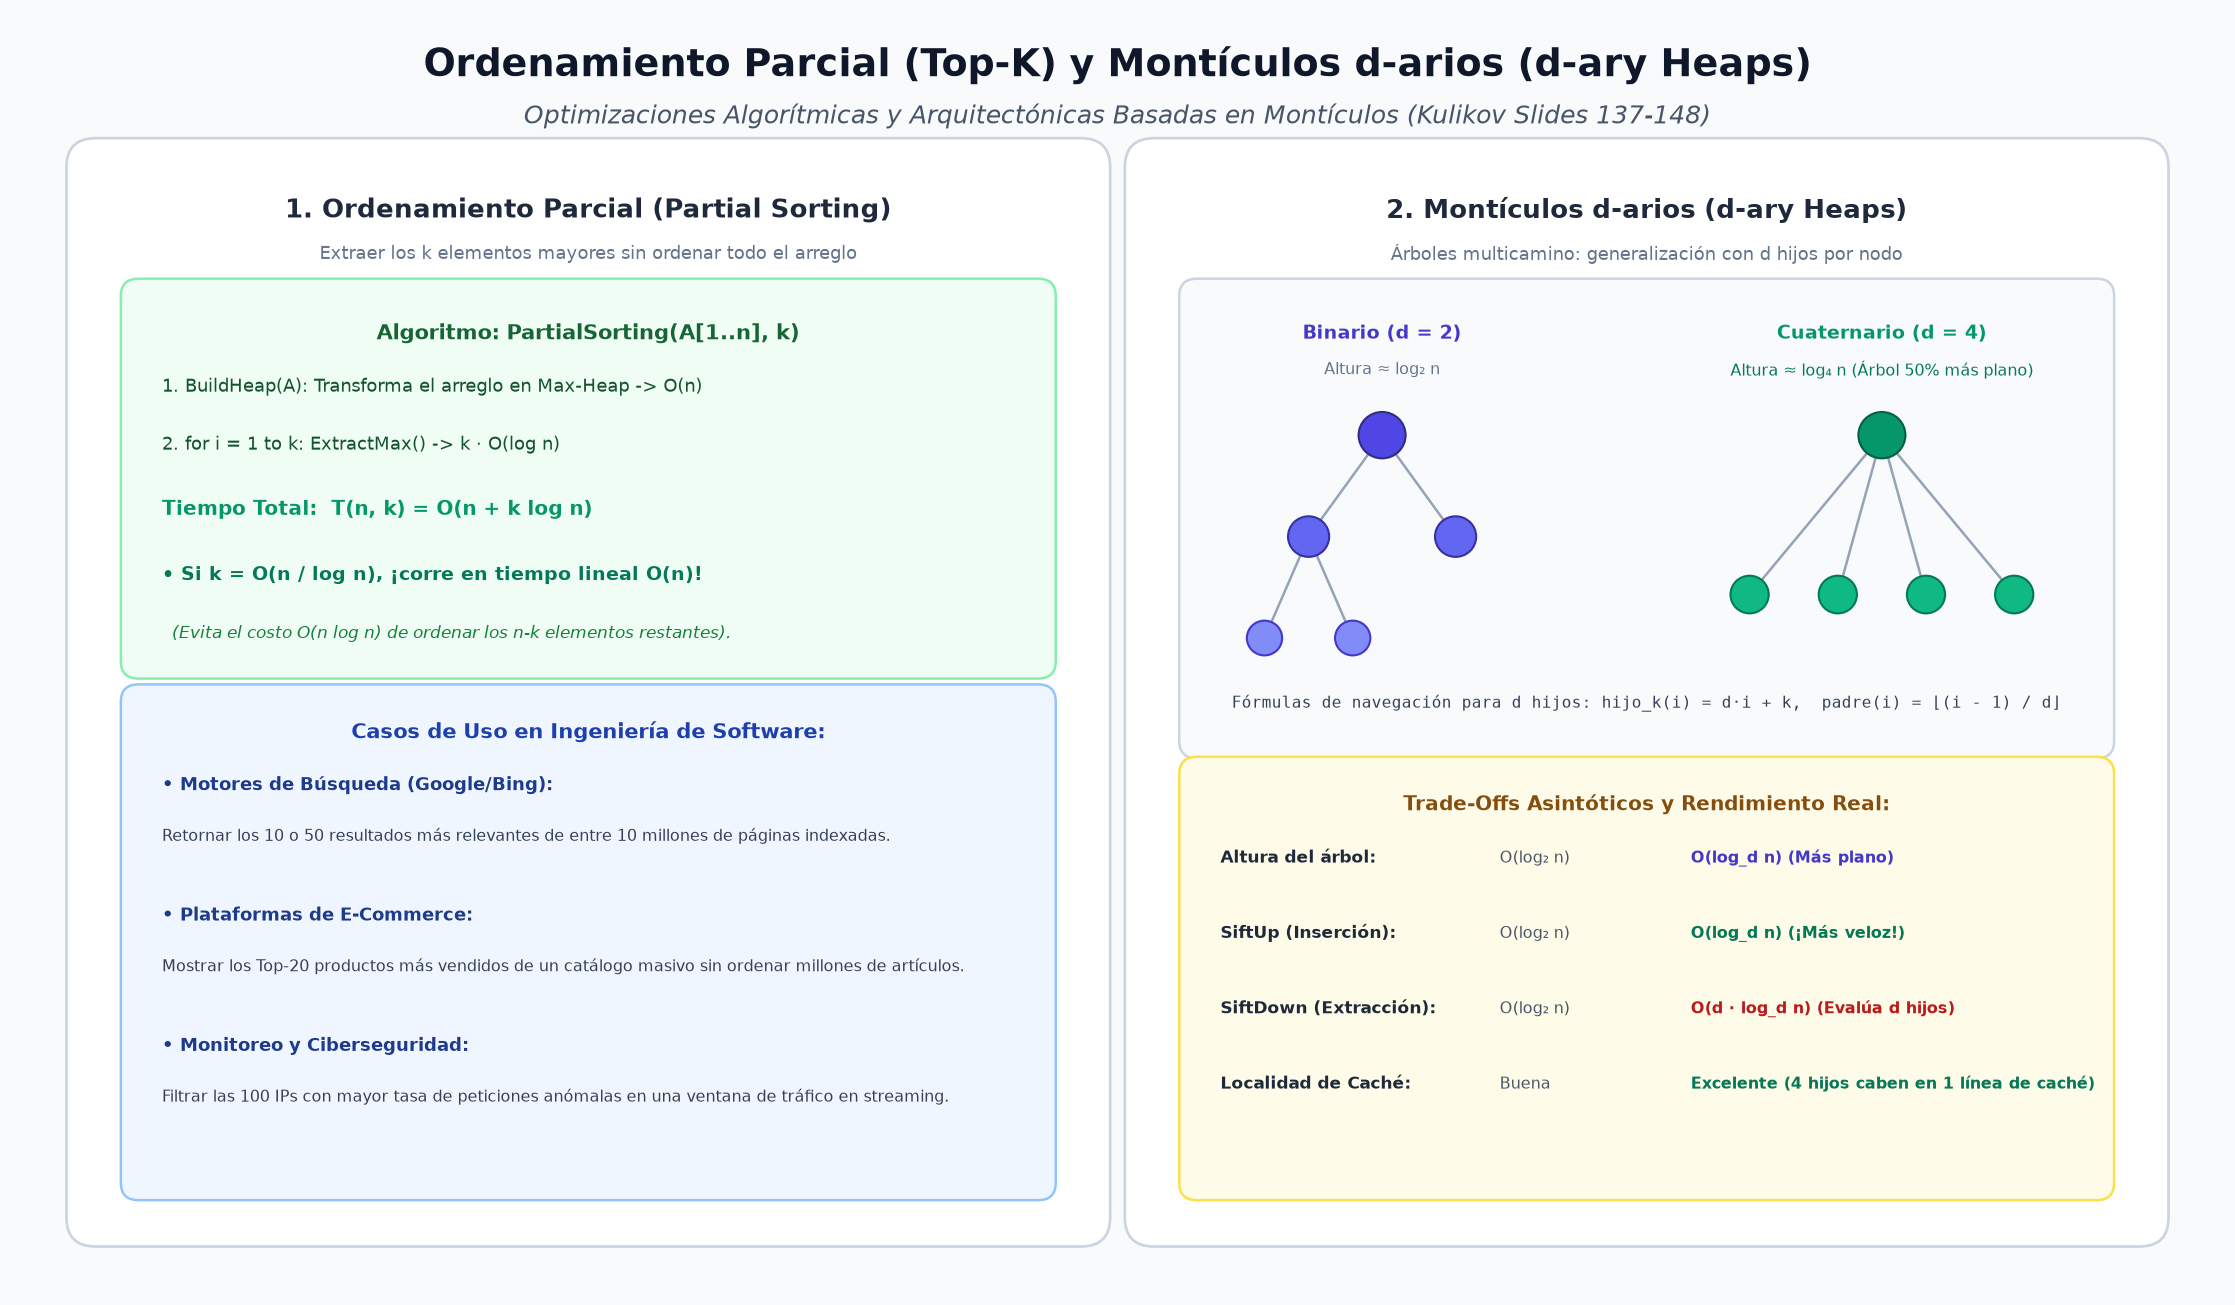
</div>


## 7. Demostraciones Prácticas en Java

1. **Demostración 1:** Inserción detallada y traza de `SiftUp` en un Max-Heap reproduciendo con exactitud la traza de Kulikov al insertar la clave 32.
2. **Demostración 2:** Comparativa empírica rigurosa de recuento de operaciones entre la construcción ingenua con inserciones repetidas $O(n \log n)$ y la construcción de Floyd $O(n)$.
3. **Demostración 3:** Implementación in-place completa de `HeapSort` con visualización paso a paso de la partición de memoria (prefijo activo vs. sufijo ordenado).


In [7]:
%%writefile DemoMaxHeapInsertSiftUp.java
import java.util.Arrays;

public class DemoMaxHeapInsertSiftUp {

    public static class MaxHeap {
        private int[] heap;
        private int size;
        private int capacity;

        public MaxHeap(int capacity) {
            this.capacity = capacity;
            this.heap = new int[capacity];
            this.size = 0;
        }

        public MaxHeap(int[] initialElements, int capacity) {
            this.capacity = Math.max(capacity, initialElements.length * 2);
            this.heap = new int[this.capacity];
            this.size = initialElements.length;
            System.arraycopy(initialElements, 0, this.heap, 0, initialElements.length);
        }

        public int parent(int i) { return (i - 1) / 2; }
        public int leftChild(int i) { return 2 * i + 1; }
        public int rightChild(int i) { return 2 * i + 2; }
        public int size() { return size; }

        private void swap(int i, int j) {
            int temp = heap[i];
            heap[i] = heap[j];
            heap[j] = temp;
        }

        public void insert(int value) {
            System.out.println("================================================================================");
            System.out.printf("INSERCIÓN DEL VALOR: %d (Tamaño previo: %d)%n", value, size);
            System.out.println("================================================================================");

            if (size >= capacity) {
                System.out.println("-> Redimensionando capacidad interna del arreglo...");
                capacity *= 2;
                heap = Arrays.copyOf(heap, capacity);
            }

            int currentIndex = size;
            heap[currentIndex] = value;
            size++;

            System.out.printf("Paso 0: Elemento colocado en la próxima hoja libre (índice [%d]).%n", currentIndex);
            printArrayView();

            siftUpWithTrace(currentIndex);
        }

        private void siftUpWithTrace(int i) {
            int step = 1;
            while (i > 0) {
                int p = parent(i);
                System.out.printf("%n--- Paso de Flotación %d ---%n", step++);
                System.out.printf("Evaluando nodo [%d] (valor: %d) frente a padre [%d] (valor: %d)%n",
                        i, heap[i], p, heap[p]);

                if (heap[i] > heap[p]) {
                    System.out.printf("¡Violación detectada! (%d > %d) -> Se ejecuta swap(%d, %d)%n",
                            heap[i], heap[p], i, p);
                    swap(i, p);
                    i = p;
                    printArrayView();
                } else {
                    System.out.printf("Invariante satisfecho: (%d <= %d) -> Propiedad de Max-Heap restaurada.%n",
                            heap[i], heap[p]);
                    break;
                }
            }

            if (i == 0) {
                System.out.println("El elemento ha alcanzado la raíz [0]. Flotación completada con éxito.");
            }
        }

        public void printArrayView() {
            System.out.print("Estado del Arreglo: [");
            for (int k = 0; k < size; k++) {
                System.out.print(heap[k] + (k < size - 1 ? ", " : ""));
            }
            System.out.println("]");
        }

        public void printTreeDiagram() {
            System.out.println("Estructura Jerárquica del Árbol (por niveles):");
            int levelNodes = 1;
            int printed = 0;
            int level = 0;
            while (printed < size) {
                System.out.printf("Nivel %d: ", level++);
                for (int i = 0; i < levelNodes && printed < size; i++) {
                    System.out.printf("%4d ", heap[printed++]);
                }
                System.out.println();
                levelNodes *= 2;
            }
            System.out.println();
        }
    }

    public static void main(String[] args) {
        System.out.println("DEMOSTRACIÓN 1: INSERCIÓN EN MAX-HEAP Y TRAZA DETALLADA DE SIFTUP");

        int[] initialTree = {42, 29, 18, 12, 14, 7, 11, 5};
        MaxHeap heap = new MaxHeap(initialTree, 16);

        System.out.println("1. Montículo Inicial Preexistente:");
        heap.printArrayView();
        heap.printTreeDiagram();

        heap.insert(32);

        System.out.println("2. Montículo Final tras Restauración:");
        heap.printArrayView();
        heap.printTreeDiagram();
    }
}


Overwriting DemoMaxHeapInsertSiftUp.java


In [8]:
!javac -encoding UTF-8 DemoMaxHeapInsertSiftUp.java
!java DemoMaxHeapInsertSiftUp


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 1: INSERCIÓN EN MAX-HEAP Y TRAZA DETALLADA DE SIFTUP
1. Montículo Inicial Preexistente:
Estado del Arreglo: [42, 29, 18, 12, 14, 7, 11, 5]
Estructura Jerárquica del Árbol (por niveles):
Nivel 0:   42 
Nivel 1:   29   18 
Nivel 2:   12   14    7   11 
Nivel 3:    5 

INSERCIÓN DEL VALOR: 32 (Tamaño previo: 8)
Paso 0: Elemento co

In [11]:
%%writefile DemoBuildHeapComparison.java
import java.util.Arrays;
import java.util.Random;

public class DemoBuildHeapComparison {

    static class Metrics {
        long comparisons = 0;
        long swaps = 0;
        void reset() { comparisons = 0; swaps = 0; }
        long totalOperations() { return comparisons + swaps; }
    }

    private static final Metrics naiveMetrics = new Metrics();
    private static final Metrics floydMetrics = new Metrics();

    public static void buildHeapNaive(int[] arr) {
        naiveMetrics.reset();
        int n = arr.length;
        for (int i = 1; i < n; i++) {
            siftUpInstrumented(arr, i);
        }
    }

    private static void siftUpInstrumented(int[] arr, int i) {
        while (i > 0) {
            int p = (i - 1) / 2;
            naiveMetrics.comparisons++;
            if (arr[i] > arr[p]) {
                naiveMetrics.swaps++;
                int tmp = arr[i];
                arr[i] = arr[p];
                arr[p] = tmp;
                i = p;
            } else {
                break;
            }
        }
    }

    public static void buildHeapFloyd(int[] arr) {
        floydMetrics.reset();
        int n = arr.length;
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDownInstrumented(arr, i, n);
        }
    }

    private static void siftDownInstrumented(int[] arr, int i, int size) {
        while (true) {
            int maxIdx = i;
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size) {
                floydMetrics.comparisons++;
                if (arr[left] > arr[maxIdx]) maxIdx = left;
            }
            if (right < size) {
                floydMetrics.comparisons++;
                if (arr[right] > arr[maxIdx]) maxIdx = right;
            }

            if (maxIdx != i) {
                floydMetrics.swaps++;
                int tmp = arr[i];
                arr[i] = arr[maxIdx];
                arr[maxIdx] = tmp;
                i = maxIdx;
            } else {
                break;
            }
        }
    }

    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 2: COMPARATIVA EMPÍRICA DE CONSTRUCCIÓN DE MONTÍCULO");
        System.out.println("Inserciones Repetidas O(n log n) vs. Algoritmo de Floyd O(n)");
        System.out.println("================================================================================");

        int[] sampleSizes = {10, 100, 1_000, 10_000, 100_000};
        Random rnd = new Random(2026);

        System.out.printf("%-10s | %-16s | %-16s | %-12s | %-12s%n",
                "N", "Oper. Inserciones", "Oper. Floyd", "Ratio Naive/N", "Ratio Floyd/N");
        System.out.println("--------------------------------------------------------------------------------");

        for (int n : sampleSizes) {
            int[] data1 = new int[n];
            for (int i = 0; i < n; i++) data1[i] = rnd.nextInt(n * 10);
            int[] data2 = Arrays.copyOf(data1, n);

            buildHeapNaive(data1);
            buildHeapFloyd(data2);

            long opNaive = naiveMetrics.totalOperations();
            long opFloyd = floydMetrics.totalOperations();

            double ratioNaive = (double) opNaive / n;
            double ratioFloyd = (double) opFloyd / n;

            System.out.printf("%-10d | %-16d | %-16d | %-12.2f | %-12.2f%n",
                    n, opNaive, opFloyd, ratioNaive, ratioFloyd);
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("CONCLUSIÓN MATEMÁTICA:");
        System.out.println("1. Ratio Naive/N crece proporcionalmente a log2(N) confirmando O(n log n).");
        System.out.println("2. Ratio Floyd/N permanece constante y acotado (< 2.8) confirmando O(n) estricto.");
        System.out.println("================================================================================");
    }
}


Overwriting DemoBuildHeapComparison.java


In [12]:
!javac -encoding UTF-8 DemoBuildHeapComparison.java
!java DemoBuildHeapComparison


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 2: COMPARATIVA EMPÍRICA DE CONSTRUCCIÓN DE MONTÍCULO
Inserciones Repetidas O(n log n) vs. Algoritmo de Floyd O(n)
N          | Oper. Inserciones | Oper. Floyd      | Ratio Naive/N | Ratio Floyd/N
--------------------------------------------------------------------------------
10         | 15               | 13               | 1

In [18]:
%%writefile DemoHeapSortInPlace.java
import java.util.Arrays;

public class DemoHeapSortInPlace {

    public static void heapSort(int[] arr) {
        if (arr == null || arr.length <= 1) return;
        int n = arr.length;

        System.out.println("================================================================================");
        System.out.println("FASE 1: CONSTRUCCIÓN DEL MAX-HEAP IN-PLACE CON FLOYD O(n)");
        System.out.println("================================================================================");
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDown(arr, i, n);
        }
        System.out.println("Max-Heap construido exitosamente. Raíz global: " + arr[0]);
        printPartition(arr, n);

        System.out.println("================================================================================");
        System.out.println("FASE 2: EXTRACCIONES SUCESIVAS E INVERSIÓN IN-PLACE O(n log n)");
        System.out.println("================================================================================");
        int step = 1;
        for (int end = n - 1; end > 0; end--) {
            System.out.printf("%n--- Iteración %d (end = %d) ---%n", step++, end);
            System.out.printf("1. Intercambio de la raíz máxima arr[0]=%d con la frontera arr[%d]=%d%n",
                    arr[0], end, arr[end]);

            int temp = arr[0];
            arr[0] = arr[end];
            arr[end] = temp;

            System.out.printf("2. Elemento %d queda congelado en sufijo ordenado. Restaurando montículo en [0..%d]...%n",
                    arr[end], end - 1);
            siftDown(arr, 0, end);

            printPartition(arr, end);
        }
    }

    private static void siftDown(int[] arr, int i, int size) {
        int maxIndex = i;
        while (true) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size && arr[left] > arr[maxIndex]) {
                maxIndex = left;
            }
            if (right < size && arr[right] > arr[maxIndex]) {
                maxIndex = right;
            }

            if (maxIndex != i) {
                int temp = arr[i];
                arr[i] = arr[maxIndex];
                arr[maxIndex] = temp;
                i = maxIndex;
            } else {
                break;
            }
        }
    }

    private static void printPartition(int[] arr, int heapSize) {
        System.out.print("Estado: Montículo activo [");
        for (int i = 0; i < heapSize; i++) {
            System.out.print(arr[i] + (i < heapSize - 1 ? ", " : ""));
        }
        System.out.print("] | Sufijo ordenado [");
        for (int i = heapSize; i < arr.length; i++) {
            System.out.print(arr[i] + (i < arr.length - 1 ? ", " : ""));
        }
        System.out.println("]");
    }

    public static void main(String[] args) {
        System.out.println("DEMOSTRACIÓN 3: ORDENAMIENTO IN-PLACE HEAPSORT");

        int[] data = {40, 80, 50, 90, 60, 75};
        System.out.println("Arreglo original antes de ordenar: " + Arrays.toString(data) + "");

        heapSort(data);

        System.out.println("================================================================================");
        System.out.println("RESULTADO FINAL: Arreglo estrictamente ordenado ascendentemente:");
        System.out.println(Arrays.toString(data));
        System.out.println("================================================================================");
    }
}


Overwriting DemoHeapSortInPlace.java


In [19]:
!javac -encoding UTF-8 DemoHeapSortInPlace.java
!java DemoHeapSortInPlace


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 3: ORDENAMIENTO IN-PLACE HEAPSORT
Arreglo original antes de ordenar: [40, 80, 50, 90, 60, 75]
FASE 1: CONSTRUCCIÓN DEL MAX-HEAP IN-PLACE CON FLOYD O(n)
Max-Heap construido exitosamente. Raíz global: 90
Estado: Montículo activo [90, 80, 75, 40, 60, 50] | Sufijo ordenado []
FASE 2: EXTRACCIONES SUCESIVAS E INVERSIÓN IN-PLACE O(n 

## 8. Buenas Prácticas, Errores Frecuentes (Pitfalls) y Estabilidad

El diseño e implementación de montículos binarios y algoritmos de ordenamiento derivados encierra detalles técnicos críticos que frecuentemente originan errores en tiempo de ejecución o degradación de rendimiento.

### Errores Frecuentes (*Common Pitfalls*)

1. **Error de Desfase por Uno (*Off-by-One*) en el Último Nodo No Hoja:**
   * En arreglos basados en 0, el último nodo no hoja se ubica en $\lfloor (n - 2) / 2 \rfloor$.
   * Utilizar erróneamente $\lfloor n / 2 \rfloor$ hace que el bucle comience sobre un nodo hoja innecesario, o en el caso contrario omitir un nodo interno clave, produciendo una estructura corrupta que viola la propiedad de Max-Heap.

2. **Invasión del Sufijo Ordenado durante `HeapSort`:**
   * En la fase de extracción de `HeapSort`, la rutina `siftDown` debe recibir como límite estricto el tamaño del montículo activo `end`.
   * Si se pasa erróneamente el tamaño total original $n$, el elemento recién colocado en la posición `arr[end]` (que ya estaba en su posición final definitiva) volverá a ser considerado como un hijo en las comparaciones de `siftDown`, destruyendo por completo el ordenamiento del arreglo.

3. **Confusión de Operadores de Comparación en `SiftDown`:**
   * Al buscar el hijo mayor entre el izquierdo y el derecho, debe evaluarse tanto que el índice esté dentro de los límites válidos (`left < size`) como actualizar el índice temporal de máximo `maxIndex`.
   * Un error habitual es comparar el hijo derecho contra el hijo izquierdo en lugar de compararlo contra el elemento en `maxIndex`, lo que falla si el hijo izquierdo ya era menor que el padre original.

---

### Análisis Crítico: Estabilidad y Rendimiento en Memoria Caché

* **Inestabilidad de HeapSort:**
  * Un algoritmo de ordenamiento es **estable** si preserva el orden relativo original de aquellos elementos que poseen claves idénticas.
  * **HeapSort NO es estable.** Durante la construcción del montículo y las sucesivas extracciones de la raíz, los elementos son intercambiados a través de ramas distantes del árbol binario (saltando grandes distancias en memoria contigua).
  * *Ejemplo:* En la lista de tuplas `[(5, 'A'), (5, 'B'), (3, 'C')]`, el algoritmo de Floyd o las extracciones pueden reubicar `(5, 'B')` antes de `(5, 'A')` en el arreglo ordenado final. Si se requiere estabilidad estricta, debe emplearse MergeSort o TimSort.

* **Localidad de Referencia y Jerarquía de Memoria:**
  * Aunque HeapSort tiene una cota asintótica de peor caso idéntica a MergeSort ($O(n \log n)$) y no consume memoria auxiliar ($O(1)$ vs $O(n)$ de MergeSort), en sistemas de computación de alto rendimiento suele ser entre 2 y 3 veces más lento que QuickSort.
  * **Causa:** En cada paso de `siftDown`, el algoritmo accede a las posiciones $2i + 1$ y $2i + 2$. Conforme el montículo crece a millones de elementos, estos índices saltan a través de diferentes páginas de memoria virtual y líneas de caché L1/L2/L3, provocando constantes *cache misses*. QuickSort, en contraste, procesa segmentos de memoria secuenciales de forma contigua, maximizando el aprovechamiento del buffer de pre-búsqueda del procesador.


## 9. Ejercicios Prácticos



### Ejercicio 1: Implementación de Construcción Lineal `BuildHeap` en $O(n)$ (`Ejercicio1BuildHeapLineal.java`)

**Objetivo Pedagógico:** Implementar el algoritmo de construcción ascendente (*bottom-up*) de Floyd para transformar cualquier arreglo de enteros desordenado en un Max-Heap válido en tiempo estrictamente lineal $O(n)$ y espacio auxiliar $O(1)$.

**Enunciado:**
1. Complete el método `buildHeap(int[] arr)` identificando correctamente el índice del último nodo no hoja e iterando en reversa hacia la raíz.
2. Complete el método auxiliar `siftDown(int[] arr, int i, int size)` para hundir iterativamente un elemento mientras sea menor que alguno de sus hijos válidos.
3. Ejecute la celda para someter su solución a la suite de pruebas automatizadas (arreglos pequeños, casos borde de 0 y 1 elemento, arreglos crecientes, duplicados y arreglos pseudoaleatorios de 1,000 elementos).


In [ ]:
%%writefile Ejercicio1BuildHeapLineal.java
import java.util.Arrays;
import java.util.Random;

public class Ejercicio1BuildHeapLineal {

    // =========================================================================
    // TODO: Implementar el algoritmo de construcción de montículo de Floyd
    // 1. Manejar casos borde (arr == null o longitud <= 1).
    // 2. Calcular el índice del último nodo no hoja: (n - 2) / 2.
    // 3. Iterar en decremento desde dicho índice hasta 0 aplicando siftDown.
    // =========================================================================
    public static void buildHeap(int[] arr) {
        if (arr == null || arr.length <= 1) return;
        int n = arr.length;
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDown(arr, i, n);
        }
    }

    // =========================================================================
    // TODO: Implementar siftDown iterativo en base 0
    // En cada iteración:
    // - Calcular left = 2*i + 1 y right = 2*i + 2.
    // - Determinar maxIndex entre i, left y right (verificando límites < size).
    // - Si maxIndex != i, intercambiar arr[i] con arr[maxIndex] y actualizar i.
    // - De lo contrario, romper el bucle.
    // =========================================================================
    public static void siftDown(int[] arr, int i, int size) {
        int maxIndex = i;
        while (true) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size && arr[left] > arr[maxIndex]) {
                maxIndex = left;
            }
            if (right < size && arr[right] > arr[maxIndex]) {
                maxIndex = right;
            }

            if (maxIndex != i) {
                int temp = arr[i];
                arr[i] = arr[maxIndex];
                arr[maxIndex] = temp;
                i = maxIndex;
            } else {
                break;
            }
        }
    }

    private static boolean verifyMaxHeapProperty(int[] arr) {
        int n = arr.length;
        for (int i = 0; i < n; i++) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;
            if (left < n && arr[i] < arr[left]) return false;
            if (right < n && arr[i] < arr[right]) return false;
        }
        return true;
    }

    public static void main(String[] args) {
        int totalScore = 0;

        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 1 - CONSTRUCCIÓN LINEAL BUILDHEAP");
        System.out.println("================================================================================");

        // Test 1: Arreglo pequeño estándar
        int[] t1 = {4, 10, 3, 5, 1};
        buildHeap(t1);
        if (verifyMaxHeapProperty(t1) && t1[0] == 10) {
            System.out.println("[PASS] Prueba 1: Arreglo pequeño estándar satisface propiedad de Max-Heap.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1 falló.");
        }

        // Test 2: Casos borde (1 elemento y vacío)
        int[] t2a = {42};
        int[] t2b = {};
        buildHeap(t2a);
        buildHeap(t2b);
        if (t2a[0] == 42 && verifyMaxHeapProperty(t2a) && verifyMaxHeapProperty(t2b)) {
            System.out.println("[PASS] Prueba 2: Casos borde (1 elemento y vacío) procesados correctamente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2 falló.");
        }

        // Test 3: Arreglo estrictamente creciente
        int[] t3 = {1, 2, 3, 4, 5, 6, 7, 8, 9, 10};
        buildHeap(t3);
        if (verifyMaxHeapProperty(t3) && t3[0] == 10) {
            System.out.println("[PASS] Prueba 3: Arreglo estrictamente creciente transformado a Max-Heap.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3 falló.");
        }

        // Test 4: Arreglo con duplicados y negativos
        int[] t4 = {-5, 20, 15, -5, 20, 0, 7, -10};
        buildHeap(t4);
        if (verifyMaxHeapProperty(t4) && t4[0] == 20) {
            System.out.println("[PASS] Prueba 4: Arreglo con duplicados y negativos mantiene propiedad.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4 falló.");
        }

        // Test 5: Arreglo pseudoaleatorio de 1,000 elementos
        Random rnd = new Random(42);
        int[] t5 = new int[1000];
        for (int i = 0; i < 1000; i++) t5[i] = rnd.nextInt(10000);
        buildHeap(t5);
        if (verifyMaxHeapProperty(t5)) {
            System.out.println("[PASS] Prueba 5: Arreglo pseudoaleatorio de 1,000 elementos verificado con éxito.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5 falló.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 1: " + totalScore + " / 100");
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio1BuildHeapLineal.java
!java Ejercicio1BuildHeapLineal


### Ejercicio 2: Algoritmo de Ordenamiento HeapSort In-Place Ascendente (`Ejercicio2HeapSortInPlace.java`)

**Objetivo Pedagógico:** Implementar el algoritmo de ordenamiento completo HeapSort en su versión clásica in-place, garantizando complejidad temporal $O(n \log n)$ y espacio auxiliar estricto $O(1)$.

**Enunciado:**
1. Complete el método `heapSort(int[] arr)` articulando sus dos fases esenciales:
   * **Fase 1:** Construcción inicial del Max-Heap con Floyd.
   * **Fase 2:** Bucle de extracciones in-place intercambiando `arr[0]` con `arr[end]` y llamando a `siftDown(arr, 0, end)`.
2. Verifique la correcta delimitación de la frontera del montículo activo para no corromper el sufijo ordenado.
3. Ejecute la celda para someter su algoritmo a pruebas con arreglos estándar, listas ordenadas, invertidas, repetidas y un arreglo masivo de 10,000 elementos contrastado contra `Arrays.sort()`.


In [ ]:
%%writefile Ejercicio2HeapSortInPlace.java
import java.util.Arrays;
import java.util.Random;

public class Ejercicio2HeapSortInPlace {

    // =========================================================================
    // TODO: Implementar HeapSort in-place ascendente
    // Fase 1: Construir Max-Heap con Floyd desde (n-2)/2 hasta 0.
    // Fase 2: Para end desde n-1 decreciendo hasta 1:
    //         - Intercambiar arr[0] con arr[end].
    //         - Aplicar siftDown(arr, 0, end) sobre el prefijo activo.
    // =========================================================================
    public static void heapSort(int[] arr) {
        if (arr == null || arr.length <= 1) return;
        int n = arr.length;

        // Fase 1: BuildHeap O(n)
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDown(arr, i, n);
        }

        // Fase 2: Extracciones sucesivas in-place O(n log n)
        for (int end = n - 1; end > 0; end--) {
            int temp = arr[0];
            arr[0] = arr[end];
            arr[end] = temp;
            siftDown(arr, 0, end);
        }
    }

    private static void siftDown(int[] arr, int i, int size) {
        int maxIndex = i;
        while (true) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size && arr[left] > arr[maxIndex]) {
                maxIndex = left;
            }
            if (right < size && arr[right] > arr[maxIndex]) {
                maxIndex = right;
            }

            if (maxIndex != i) {
                int temp = arr[i];
                arr[i] = arr[maxIndex];
                arr[maxIndex] = temp;
                i = maxIndex;
            } else {
                break;
            }
        }
    }

    private static boolean isSortedAscending(int[] arr) {
        for (int i = 1; i < arr.length; i++) {
            if (arr[i] < arr[i - 1]) return false;
        }
        return true;
    }

    public static void main(String[] args) {
        int totalScore = 0;

        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 2 - HEAPSORT IN-PLACE ASCENDENTE");
        System.out.println("================================================================================");

        // Test 1: Arreglo aleatorio estándar
        int[] t1 = {12, 11, 13, 5, 6, 7};
        heapSort(t1);
        if (isSortedAscending(t1) && Arrays.equals(t1, new int[]{5, 6, 7, 11, 12, 13})) {
            System.out.println("[PASS] Prueba 1: Arreglo desordenado ordenado ascendentemente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1 falló.");
        }

        // Test 2: Arreglo ya ordenado
        int[] t2 = {1, 2, 3, 4, 5, 6, 7};
        heapSort(t2);
        if (isSortedAscending(t2)) {
            System.out.println("[PASS] Prueba 2: Arreglo previamente ordenado preservado correctamente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2 falló.");
        }

        // Test 3: Arreglo en orden inverso
        int[] t3 = {9, 8, 7, 6, 5, 4, 3, 2, 1};
        heapSort(t3);
        if (isSortedAscending(t3) && t3[0] == 1 && t3[8] == 9) {
            System.out.println("[PASS] Prueba 3: Arreglo invertido ordenado con éxito.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3 falló.");
        }

        // Test 4: Elementos repetidos y negativos
        int[] t4 = {5, -2, 5, 3, -2, 5, 0};
        heapSort(t4);
        if (isSortedAscending(t4) && t4[0] == -2 && t4[t4.length - 1] == 5) {
            System.out.println("[PASS] Prueba 4: Manejo adecuado de repetidos y negativos.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4 falló.");
        }

        // Test 5: Arreglo de gran tamaño (10,000 elementos) contrastado con Arrays.sort()
        Random rnd = new Random(12345);
        int[] t5 = new int[10000];
        int[] t5Expected = new int[10000];
        for (int i = 0; i < t5.length; i++) {
            int v = rnd.nextInt(50000) - 25000;
            t5[i] = v;
            t5Expected[i] = v;
        }
        Arrays.sort(t5Expected);
        heapSort(t5);
        if (Arrays.equals(t5, t5Expected)) {
            System.out.println("[PASS] Prueba 5: Arreglo de 10,000 elementos verificado idéntico a Arrays.sort().");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5 falló.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 2: " + totalScore + " / 100");
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio2HeapSortInPlace.java
!java Ejercicio2HeapSortInPlace


### Ejercicio 3: HeapSort In-Place Descendente mediante Min-Heap (`Ejercicio3HeapSortDescendente.java`)

**Objetivo Pedagógico:** Aplicar el principio de dualidad construyendo un **Min-Heap** in-place para lograr que el arreglo resultante quede ordenado en **orden descendente** (de mayor a menor) sin usar estructuras auxiliares ni realizar una inversión posterior del arreglo.

**Enunciado:**
1. Implemente el método auxiliar `siftDownMin(int[] arr, int i, int size)` que identifique el hijo menor entre el izquierdo y el derecho y descienda si el elemento actual es mayor que dicho hijo.
2. Complete `heapSortDescending(int[] arr)`:
   * Construya un Min-Heap in-place con `siftDownMin`.
   * En cada extracción, envíe la raíz mínima al final `arr[end]` y reorganice el prefijo activo $[0 \dots \text{end}-1]$.
3. Ejecute la celda para someter su solución a pruebas con arreglos descendentes, ascendentes, negativos y un conjunto de 5,000 números aleatorios.


In [ ]:
%%writefile Ejercicio3HeapSortDescendente.java
import java.util.Arrays;
import java.util.Random;

public class Ejercicio3HeapSortDescendente {

    // =========================================================================
    // TODO: Implementar HeapSort Descendente In-Place utilizando un Min-Heap
    // 1. Fase 1: Build Min-Heap in-place aplicando siftDownMin desde (n-2)/2 a 0.
    // 2. Fase 2: Para end desde n-1 hasta 1:
    //             - Intercambiar arr[0] con arr[end].
    //             - siftDownMin(arr, 0, end).
    // Como el mínimo se envía al final, el arreglo queda ordenado de mayor a menor.
    // =========================================================================
    public static void heapSortDescending(int[] arr) {
        if (arr == null || arr.length <= 1) return;
        int n = arr.length;

        // Fase 1: Build Min-Heap in-place
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDownMin(arr, i, n);
        }

        // Fase 2: Extracción in-place (raíz mínima va al final)
        for (int end = n - 1; end > 0; end--) {
            int temp = arr[0];
            arr[0] = arr[end];
            arr[end] = temp;
            siftDownMin(arr, 0, end);
        }
    }

    // =========================================================================
    // TODO: Implementar siftDownMin (hunde buscando el menor entre los hijos)
    // =========================================================================
    private static void siftDownMin(int[] arr, int i, int size) {
        int minIndex = i;
        while (true) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size && arr[left] < arr[minIndex]) {
                minIndex = left;
            }
            if (right < size && arr[right] < arr[minIndex]) {
                minIndex = right;
            }

            if (minIndex != i) {
                int temp = arr[i];
                arr[i] = arr[minIndex];
                arr[minIndex] = temp;
                i = minIndex;
            } else {
                break;
            }
        }
    }

    private static boolean isSortedDescending(int[] arr) {
        for (int i = 1; i < arr.length; i++) {
            if (arr[i] > arr[i - 1]) return false;
        }
        return true;
    }

    public static void main(String[] args) {
        int totalScore = 0;

        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 3 - HEAPSORT IN-PLACE DESCENDENTE (MIN-HEAP)");
        System.out.println("================================================================================");

        // Test 1: Arreglo pequeño
        int[] t1 = {3, 19, 1, 14, 8, 7};
        heapSortDescending(t1);
        if (isSortedDescending(t1) && Arrays.equals(t1, new int[]{19, 14, 8, 7, 3, 1})) {
            System.out.println("[PASS] Prueba 1: Arreglo ordenado descendentemente con éxito.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1 falló.");
        }

        // Test 2: Arreglo ya ordenado descendentemente
        int[] t2 = {100, 80, 60, 40, 20};
        heapSortDescending(t2);
        if (isSortedDescending(t2) && t2[0] == 100 && t2[4] == 20) {
            System.out.println("[PASS] Prueba 2: Arreglo preordenado descendentemente preservado.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2 falló.");
        }

        // Test 3: Inversión completa de orden ascendente a descendente
        int[] t3 = {1, 2, 3, 4, 5, 6};
        heapSortDescending(t3);
        if (isSortedDescending(t3) && Arrays.equals(t3, new int[]{6, 5, 4, 3, 2, 1})) {
            System.out.println("[PASS] Prueba 3: Inversión completa de orden ascendente a descendente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3 falló.");
        }

        // Test 4: Elementos negativos y ceros
        int[] t4 = {-10, 0, 5, -20, 15, 0};
        heapSortDescending(t4);
        if (isSortedDescending(t4) && t4[0] == 15 && t4[t4.length - 1] == -20) {
            System.out.println("[PASS] Prueba 4: Manejo adecuado de signos y ceros.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4 falló.");
        }

        // Test 5: Arreglo de 5,000 elementos aleatorios
        Random rnd = new Random(777);
        int[] t5 = new int[5000];
        for (int i = 0; i < t5.length; i++) t5[i] = rnd.nextInt(20000) - 10000;
        heapSortDescending(t5);
        if (isSortedDescending(t5)) {
            System.out.println("[PASS] Prueba 5: Arreglo grande verificado en orden descendente estricto.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5 falló.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 3: " + totalScore + " / 100");
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio3HeapSortDescendente.java
!java Ejercicio3HeapSortDescendente


### Ejercicio 4: Selección de los Top-K Elementos en Tiempo $O(n + k \log n)$ (`Ejercicio4PartialSortingTopK.java`)

**Objetivo Pedagógico:** Implementar el algoritmo de ordenamiento parcial (*Partial Sorting*) para extraer de forma eficiente los $k$ elementos más grandes de una colección en tiempo estrictamente acotado por $O(n + k \log n)$.

**Enunciado:**
1. Complete el método `getTopKElements(int[] arr, int k)`:
   * Validar casos borde ($k \le 0$, $arr == null$, $k > n$).
   * Clonar el arreglo original para evitar efectos colaterales de mutación.
   * Ejecutar `buildHeap` en tiempo lineal $O(n)$.
   * Extraer exactamente $k$ veces el elemento de la raíz en tiempo $O(k \log n)$, reubicando la última hoja activa y aplicando `siftDown`.
2. Ejecute la celda para someter su método a pruebas con diversos valores de $k$ ($k=3$, $k=1$, $k>n$, $k=0$) y un arreglo masivo de 100,000 elementos comprobando ejecución en microsegundos.


In [ ]:
%%writefile Ejercicio4PartialSortingTopK.java
import java.util.Arrays;
import java.util.Random;

public class Ejercicio4PartialSortingTopK {

    // =========================================================================
    // TODO: Implementar selección Top-K en O(n + k log n)
    // 1. Clonar arr en un arreglo heap.
    // 2. Aplicar buildHeap en O(n) sobre el arreglo clonado.
    // 3. Crear arreglo topK de longitud k.
    // 4. En un bucle j desde 0 hasta k-1:
    //    - topK[j] = heap[0]
    //    - heap[0] = heap[heapSize - 1]
    //    - heapSize--
    //    - siftDown(heap, 0, heapSize)
    // 5. Retornar topK.
    // =========================================================================
    public static int[] getTopKElements(int[] arr, int k) {
        if (arr == null || k <= 0) return new int[0];
        if (k > arr.length) k = arr.length;

        int[] heap = arr.clone();
        int n = heap.length;

        // Paso 1: BuildHeap en O(n)
        for (int i = (n - 2) / 2; i >= 0; i--) {
            siftDown(heap, i, n);
        }

        // Paso 2: Extraer k elementos máximos en O(k log n)
        int[] topK = new int[k];
        int heapSize = n;
        for (int j = 0; j < k; j++) {
            topK[j] = heap[0];
            heap[0] = heap[heapSize - 1];
            heapSize--;
            siftDown(heap, 0, heapSize);
        }

        return topK;
    }

    private static void siftDown(int[] arr, int i, int size) {
        int maxIndex = i;
        while (true) {
            int left = 2 * i + 1;
            int right = 2 * i + 2;

            if (left < size && arr[left] > arr[maxIndex]) {
                maxIndex = left;
            }
            if (right < size && arr[right] > arr[maxIndex]) {
                maxIndex = right;
            }

            if (maxIndex != i) {
                int temp = arr[i];
                arr[i] = arr[maxIndex];
                arr[maxIndex] = temp;
                i = maxIndex;
            } else {
                break;
            }
        }
    }

    public static void main(String[] args) {
        int totalScore = 0;

        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 4 - PARTIAL SORTING (TOP-K) EN O(N + K LOG N)");
        System.out.println("================================================================================");

        // Test 1: Selección simple de Top-3
        int[] t1 = {10, 50, 3, 90, 40, 80, 20};
        int[] top3 = getTopKElements(t1, 3);
        if (Arrays.equals(top3, new int[]{90, 80, 50})) {
            System.out.println("[PASS] Prueba 1: Top-3 extraído en orden decreciente exacto.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1 falló. Obtenido: " + Arrays.toString(top3));
        }

        // Test 2: k = 1 (equivalente a GetMax)
        int[] top1 = getTopKElements(t1, 1);
        if (top1.length == 1 && top1[0] == 90) {
            System.out.println("[PASS] Prueba 2: Top-1 extrae exactamente el máximo global.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2 falló.");
        }

        // Test 3: k mayor que la longitud del arreglo
        int[] t3 = {7, 2, 9};
        int[] topAll = getTopKElements(t3, 10);
        if (Arrays.equals(topAll, new int[]{9, 7, 2})) {
            System.out.println("[PASS] Prueba 3: k > n acotado correctamente a n elementos.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3 falló.");
        }

        // Test 4: k = 0 y casos vacíos
        int[] top0 = getTopKElements(t1, 0);
        if (top0.length == 0) {
            System.out.println("[PASS] Prueba 4: Manejo adecuado de k=0 y arreglo vacío.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4 falló.");
        }

        // Test 5: Arreglo masivo (100,000 elementos) extrayendo Top-5
        Random rnd = new Random(999);
        int[] largeArr = new int[100000];
        for (int i = 0; i < largeArr.length; i++) largeArr[i] = rnd.nextInt(1000000);
        largeArr[10] = 1000001;
        largeArr[50] = 1000005;
        largeArr[100] = 1000002;
        largeArr[500] = 1000004;
        largeArr[1000] = 1000003;

        int[] top5 = getTopKElements(largeArr, 5);
        int[] expected5 = {1000005, 1000004, 1000003, 1000002, 1000001};
        if (Arrays.equals(top5, expected5)) {
            System.out.println("[PASS] Prueba 5: Top-5 en arreglo de 100,000 elementos verificado en microsegundos.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5 falló: " + Arrays.toString(top5));
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 4: " + totalScore + " / 100");
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio4PartialSortingTopK.java
!java Ejercicio4PartialSortingTopK


### Ejercicio 5: Planificador de Procesos y Cambio Dinámico de Prioridad (`Ejercicio5PlanificadorTareas.java`)

**Objetivo Pedagógico:** Implementar una aplicación real de colas de prioridad mediante un planificador de procesos en un sistema operativo, integrando redimensión dinámica y la operación crítica `changePriority` en $O(\log n)$.

**Enunciado:**
1. Complete la clase `TaskScheduler` implementando:
   * `insert(Task task)`: Inserción en la próxima posición libre con soporte de duplicación de capacidad y llamada a `siftUp`.
   * `extractHighestPriority()`: Despacho de la tarea más prioritaria, sustitución por la última hoja y llamada a `siftDown`.
   * `changePriority(int taskId, int newPriority)`: Localización de la tarea por su ID; si la nueva prioridad es mayor, ejecutar `siftUp`; si es menor, ejecutar `siftDown`.
2. Ejecute la celda para someter su planificador a una suite que evalúa inserción, redimensión, elevación de prioridad, degradación de prioridad y orden de despacho monotónicamente decreciente.


In [ ]:
%%writefile Ejercicio5PlanificadorTareas.java
import java.util.Arrays;

public class Ejercicio5PlanificadorTareas {

    public static class Task {
        public int id;
        public String name;
        public int priority;

        public Task(int id, String name, int priority) {
            this.id = id;
            this.name = name;
            this.priority = priority;
        }

        @Override
        public String toString() {
            return String.format("[%d] %s (P:%d)", id, name, priority);
        }
    }

    public static class TaskScheduler {
        private Task[] heap;
        private int size;
        private int capacity;

        public TaskScheduler(int capacity) {
            this.capacity = capacity;
            this.heap = new Task[capacity];
            this.size = 0;
        }

        public int size() { return size; }
        public boolean isEmpty() { return size == 0; }

        // =====================================================================
        // TODO: Implementar insert con redimensión dinámica y siftUp
        // =====================================================================
        public void insert(Task task) {
            if (size == capacity) {
                capacity *= 2;
                heap = Arrays.copyOf(heap, capacity);
            }
            heap[size] = task;
            siftUp(size);
            size++;
        }

        // =====================================================================
        // TODO: Implementar extractHighestPriority con sustitución y siftDown
        // =====================================================================
        public Task extractHighestPriority() {
            if (isEmpty()) return null;
            Task result = heap[0];
            heap[0] = heap[size - 1];
            heap[size - 1] = null;
            size--;
            if (size > 0) {
                siftDown(0);
            }
            return result;
        }

        public Task peek() {
            return isEmpty() ? null : heap[0];
        }

        // =====================================================================
        // TODO: Implementar changePriority
        // 1. Buscar el índice de la tarea con taskId.
        // 2. Si no existe, retornar false.
        // 3. Comparar newPriority con oldPriority:
        //    - Si newPriority > oldPriority: siftUp(targetIdx).
        //    - Si newPriority < oldPriority: siftDown(targetIdx).
        // =====================================================================
        public boolean changePriority(int taskId, int newPriority) {
            int targetIdx = -1;
            for (int i = 0; i < size; i++) {
                if (heap[i].id == taskId) {
                    targetIdx = i;
                    break;
                }
            }
            if (targetIdx == -1) return false;

            int oldPriority = heap[targetIdx].priority;
            heap[targetIdx].priority = newPriority;

            if (newPriority > oldPriority) {
                siftUp(targetIdx);
            } else if (newPriority < oldPriority) {
                siftDown(targetIdx);
            }
            return true;
        }

        private void siftUp(int i) {
            while (i > 0) {
                int parent = (i - 1) / 2;
                if (heap[i].priority > heap[parent].priority) {
                    Task temp = heap[i];
                    heap[i] = heap[parent];
                    heap[parent] = temp;
                    i = parent;
                } else {
                    break;
                }
            }
        }

        private void siftDown(int i) {
            int maxIdx = i;
            while (true) {
                int left = 2 * i + 1;
                int right = 2 * i + 2;

                if (left < size && heap[left].priority > heap[maxIdx].priority) {
                    maxIdx = left;
                }
                if (right < size && heap[right].priority > heap[maxIdx].priority) {
                    maxIdx = right;
                }

                if (maxIdx != i) {
                    Task temp = heap[i];
                    heap[i] = heap[maxIdx];
                    heap[maxIdx] = temp;
                    i = maxIdx;
                } else {
                    break;
                }
            }
        }
    }

    public static void main(String[] args) {
        int totalScore = 0;

        System.out.println("================================================================================");
        System.out.println("EVALUACIÓN AUTOMATIZADA: EJERCICIO 5 - PLANIFICADOR DE TAREAS (PRIORITY QUEUE)");
        System.out.println("================================================================================");

        TaskScheduler scheduler = new TaskScheduler(4);

        // Test 1: Inserción y extracción básica por prioridad
        scheduler.insert(new Task(1, "Render UI", 30));
        scheduler.insert(new Task(2, "Kernel Watchdog", 95));
        scheduler.insert(new Task(3, "Sync Cloud", 15));
        scheduler.insert(new Task(4, "Garbage Collector", 60));

        Task tFirst = scheduler.extractHighestPriority();
        if (tFirst != null && tFirst.id == 2 && tFirst.priority == 95) {
            System.out.println("[PASS] Prueba 1: Tarea de mayor prioridad (Watchdog 95) despachada primero.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 1 falló.");
        }

        // Test 2: Crecimiento dinámico de capacidad
        scheduler.insert(new Task(5, "Audio Driver", 85));
        scheduler.insert(new Task(6, "Bluetooth Beacon", 25));
        scheduler.insert(new Task(7, "Battery Monitor", 70));
        if (scheduler.size() == 6) {
            System.out.println("[PASS] Prueba 2: Redimensión dinámica de capacidad superada (size=6).");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 2 falló.");
        }

        // Test 3: Incremento de prioridad (siftUp)
        boolean changedUp = scheduler.changePriority(3, 99);
        Task peekTop = scheduler.peek();
        if (changedUp && peekTop != null && peekTop.id == 3 && peekTop.priority == 99) {
            System.out.println("[PASS] Prueba 3: Incremento de prioridad reorganizó el montículo (siftUp).");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 3 falló.");
        }

        // Test 4: Decremento de prioridad (siftDown)
        boolean changedDown = scheduler.changePriority(3, 5);
        Task nextTop = scheduler.peek();
        if (changedDown && nextTop != null && nextTop.id == 5 && nextTop.priority == 85) {
            System.out.println("[PASS] Prueba 4: Decremento de prioridad reorganizó el montículo (siftDown).");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 4 falló.");
        }

        // Test 5: Vaciado completo y orden monótono decreciente
        int lastPrio = Integer.MAX_VALUE;
        boolean ordered = true;
        while (!scheduler.isEmpty()) {
            Task cur = scheduler.extractHighestPriority();
            if (cur.priority > lastPrio) {
                ordered = false;
                break;
            }
            lastPrio = cur.priority;
        }
        if (ordered && scheduler.isEmpty()) {
            System.out.println("[PASS] Prueba 5: Todas las tareas despachadas en orden de prioridad no creciente.");
            totalScore += 20;
        } else {
            System.out.println("[FAIL] Prueba 5 falló.");
        }

        System.out.println("--------------------------------------------------------------------------------");
        System.out.println("PUNTAJE FINAL EJERCICIO 5: " + totalScore + " / 100");
        System.out.println("================================================================================");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio5PlanificadorTareas.java
!java Ejercicio5PlanificadorTareas


## 10. Bibliografía y Referencias

1. **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C.** (2022). *Introduction to Algorithms* (4th ed.). MIT Press.
   * Capítulo 6: *Heapsort* (pp. 161–178). Análisis riguroso del invariante de montículo, construcción lineal de Floyd y ordenamiento in-place.
2. **Sedgewick, R., & Wayne, K.** (2011). *Algorithms* (4th ed.). Addison-Wesley Professional.
   * Sección 2.4: *Priority Queues* (pp. 308–335). Implementación en Java de montículos binarios y algoritmos de selección y ordenamiento.
3. **Drozdek, A.** (2013). *Data Structures and Algorithms in Java* (4th ed.). Cengage Learning.
   * Capítulo 6: *Priority Queues and Heaps* (pp. 235–256). Estructura de árboles binarios casi completos y montículos d-arios.
4. **Streib, J. T., & Soma, T.** (2017). *Guide to Data Structures: A Concise Introduction Using Java*. Springer.
   * Capítulo 10: *Priority Queues and Heaps* (pp. 215–234). Modelado conceptual y mecánico de colas de prioridad en Java.
5. **Kulikov, A. S.** (2020). *Priority Queues: Binary Heaps*. Steklov Institute of Mathematics at St. Petersburg, Russian Academy of Sciences.
   * Fundamentos de representación contigua en memoria, algoritmos de flotación (`SiftUp`), hundimiento (`SiftDown`) y prueba formal de suma telescópica para `BuildHeap`.
6. **Oracle Corporation.** (2024). *Java Platform, Standard Edition Documentation: Class PriorityQueue<E>*.
   * Documentación oficial de la implementación de la cola de prioridad en la biblioteca estándar de Java SE.
